# 04 · Modelado de la solución

**Ciencia de Datos Aplicada (ITBA) · Tercer entregable: entrenamiento y validación del modelo**

**Equipo:** Juan Ignacio Fernández Dinardo, Gianfranco Magliotti, Santiago Joaquín Nartallo Galvagno

**Proyecto:** Modelo predictivo de demanda de Ecobici (CABA)

**Qué hace este notebook:** entrena y valida el modelo que predice la **demanda de cada estación de Ecobici, hora por hora, para el día siguiente**, y lo guarda para usarlo sin reentrenar. Con las predicciones arma las dos salidas que motivan el proyecto: qué estaciones van a quedar **vacías o llenas** (para planificar el rebalanceo) y cuáles conviene **ampliar**.

**Entrada:** `data/processed/dataset_estacion_hora.parquet` (tercer notebook): una fila por estación activa y hora, del 01/01/2024 al 31/08/2026, con la partición `train` / `test` ya hecha, y `data/processed/estaciones.csv` (nombres y ubicación de las estaciones). Las secciones 8.2 y 10.7 leen además las **fotos y los pronósticos crudos** de `datasets/archive/` (los mismos de `datasets.zip` que usa el primer notebook).

**Salidas** (en `models/`): los modelos entrenados (`.joblib`), los grupos de estaciones y un `metadata.json` con las variables, los hiperparámetros, las métricas y la consulta que arma las variables.

**Targets.** `retiros` (el target principal) y `arribos`. La diferencia `arribos − retiros` es el **flujo neto** de la estación: si es negativo la estación se vacía, si es positivo se llena.

**Tiempo de ejecución:** la mayor parte se va en los entrenamientos del boosting (secciones 7 a 10 y 12.2). Sin las secciones agregadas por la devolución del segundo entregable (8.2, 10.6, 10.7 y la sensibilidad de 12.2), tardaba unos 20 minutos en una Mac con 24 GB de RAM; esas secciones suman cinco entrenamientos. La corrida completa tardó **1 h 36 min en una notebook con 16 GB de RAM** y un procesador de 4 núcleos: la memoria no alcanza y el sistema usa el disco.

## Respuesta a la devolución del segundo entregable

| Devolución | Qué se hizo | Dónde | Resultado |
|---|---|---|---|
| *"El período de test (junio a agosto de 2026) coincide con la degradación de las fotos (...) convendría evaluar también sobre un período con buena cobertura para medir su aporte real"* | Ablación del boosting con y sin las 5 variables de estado, en tres períodos con distinta cobertura de fotos: sep–nov 2025 (3,6 fotos por estación-hora), mar–may 2026 (1,9) y el test (1,2) | 10.6 | **Con buena cobertura tampoco aportan:** sacarlas cambia la devianza en 0,0007 y el WAPE diario en 0,1 puntos. La conclusión de 10.4 no era un efecto de la cobertura. Se mantienen porque no perjudican y bajan algo el sesgo, y el modelo rinde casi igual sin ellas si el feed de fotos sigue degradándose |
| Próximo paso: rezagos | Diez variables con rezago de 24 h o más, con control de fuga de información | 2 | El promedio de la misma hora en la última semana es la segunda variable más importante (10.4) |
| Próximo paso: pronóstico en lugar de clima observado | Clima disponible al cierre del día anterior (la última versión del pronóstico publicada antes de las 00:00) y evaluación del modelo final en el test con ese clima | 10.7 | **El costo es chico en total** (WAPE diario de 29,0 % a 29,8 %) y se concentra en las horas con lluvia, que el pronóstico detecta mal: ahí el modelo sobreestima un 36 % |
| Próximo paso: tratamiento de la censura | Marca de censura medida **al inicio de la hora**, que no depende del target. Se repite el experimento de 8.1 y se recalcula la demanda perdida con ella | 8.2 y 12.2 | **Las conclusiones se mantienen:** el modelo principal sigue siendo el entrenado con todas las horas, y la demanda perdida pasa de 6,3 % a 6,6 %, con el mismo ranking de estaciones |
| Primer entregable: *las bicis rotas que ocupan lugar y no se pueden usar* | Capacidad útil y bicis rotas como variables, y censura por estación vacía o llena de rotas | 2, 8.1 y 12.2 | Resuelto en el segundo entregable; acá se usa para estimar la demanda perdida |

Los puntos nuevos son **experimentos** con los mismos modelos del resto del notebook, no técnicas nuevas: las técnicas elegidas y descartadas están justificadas en la sección 1.

**Correspondencia con la plantilla de la cátedra.** El notebook sigue el orden de la plantilla del tercer entregable, con más secciones:

| Plantilla | Secciones de este notebook |
|---|---|
| 🧾 Carga de datos y preparación | 0. Configuración · 2. Variables con rezago |
| División en entrenamiento y test | 4. Esquema de validación (partición temporal) |
| 🏋️ Entrenamiento: validación, búsqueda de hiperparámetros, al menos dos técnicas | 5. Baselines · 6. Regresión de Poisson · 7. Gradient boosting (7.1 búsqueda de hiperparámetros) |
| 🔍 Comparación de resultados y elección del modelo | 8. Validación cruzada temporal (8.1 y 8.2: censura) |
| 📐 Métricas y visualización del modelo seleccionado | 3. Métricas · 9. Evaluación en test · 10.1 a 10.3 |
| 👩‍⚕️ Análisis de los resultados | 10.4 a 10.7 · 11. Agrupamiento de estaciones · 12. Uso de la solución |
| 💾 Persistencia del modelo seleccionado | 13. Persistencia (con la prueba de carga sin reentrenar) |
| 🛫 Reflexiones finales | 14. Reflexión crítica |

Una diferencia con la plantilla: el modelo **no se elige por su resultado en test** sino con la validación cruzada temporal (sección 8). Así el test sigue siendo una medición independiente del modelo elegido.

## 0. Configuración

- **Corte de test:** desde el 01/06/2026, el mismo del tercer notebook. El test **no se usa** hasta la sección 9: toda decisión (variables, hiperparámetros, censura) se toma con el train.
- **Validación:** dentro del train, una ventana para la búsqueda de hiperparámetros (junio a agosto de 2025) y, después, tres pliegues temporales de tres meses para comparar modelos (sección 4).
- **Datos crudos:** las fotos y los pronósticos de `datasets/archive/` se leen sólo en las secciones 8.2 (censura al inicio de la hora) y 10.7 (clima pronosticado).
- **Modelos:** se usa sólo `scikit-learn`, que ya es dependencia del proyecto. El modelo principal es `HistGradientBoostingRegressor`, la implementación de *gradient boosting* por histogramas de scikit-learn, inspirada en LightGBM (ver sección 1).

In [1]:
from pathlib import Path
import json
import platform
import time
import warnings

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform, spearmanr
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import (mean_absolute_error, mean_poisson_deviance, r2_score,
                             root_mean_squared_error, silhouette_score)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

REPO_DIR = Path("..").resolve()
PROCESSED_DIR = REPO_DIR / "data" / "processed"
DATASET = PROCESSED_DIR / "dataset_estacion_hora.parquet"
MODELS_DIR = REPO_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
DATA_DIR = REPO_DIR / "datasets"  # datos crudos de datasets.zip, como en el primer notebook
FOTOS_CRUDAS = DATA_DIR / "archive" / "stations" / "buenos-aires" / "ecobici"
PRONOSTICOS = DATA_DIR / "archive" / "weather" / "buenos-aires"

TEST_DESDE = pd.Timestamp("2026-06-01")
PLIEGUES = [  # (inicio, fin) de cada ventana de validación dentro del train
    (pd.Timestamp("2025-09-01"), pd.Timestamp("2025-12-01")),
    (pd.Timestamp("2025-12-01"), pd.Timestamp("2026-03-01")),
    (pd.Timestamp("2026-03-01"), pd.Timestamp("2026-06-01")),
]
BUSQUEDA = (pd.Timestamp("2025-06-01"), pd.Timestamp("2025-09-01"))  # ventana de validación de la búsqueda
SEMILLA = 42
MUESTRA_GLM = 1_000_000  # filas para el modelo lineal (ver sección 6)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c86"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

warnings.filterwarnings("ignore", message=".*'generic' unit for NumPy timedelta.*")  # aviso interno de pandas con numpy 2

assert DATASET.exists(), f"No se encontró {DATASET}. Correr antes el notebook 03."
assert FOTOS_CRUDAS.exists() and PRONOSTICOS.exists(), f"No se encontraron los datos crudos en {DATA_DIR} (ver el README)."
print("scikit-learn", sklearn.__version__)
print("Entrada:", DATASET.relative_to(REPO_DIR))
print("Datos crudos:", DATA_DIR.relative_to(REPO_DIR))
print("Salidas:", MODELS_DIR.relative_to(REPO_DIR))

scikit-learn 1.9.1
Entrada: data\processed\dataset_estacion_hora.parquet
Datos crudos: datasets
Salidas: models


## 1. Enfoque adoptado y justificación

**Tipo de problema.** Aprendizaje **supervisado de regresión**: se conocen las variables $X$ (calendario, clima, demanda pasada, estado de la estación) y se quiere estimar un número, la cantidad de retiros (o arribos) de una estación en una hora.

**Qué se predice y cuándo.** El uso es operativo: el equipo de logística planifica el rebalanceo del día con anticipación. Por eso el modelo predice **las 24 horas del día siguiente** con lo que se sabe **al cierre del día anterior**. Esto define qué variables se pueden usar:

| Se puede usar | No se puede usar |
|---|---|
| Calendario del día a predecir (hora, día, feriado) | Retiros o arribos de las 24 h previas a la hora a predecir |
| Clima de la hora (en producción, el pronóstico) | Estado de la estación en la **misma** hora (es en parte consecuencia del target, como advirtió el tercer notebook) |
| Demanda y estado de la estación con **24 h o más** de rezago | |

**Por qué estas técnicas** (de las vistas en la clase de regresión):

| Técnica | Rol | Motivo |
|---|---|---|
| Promedios históricos y "semana anterior" | **Baselines** | Un modelo sólo vale si le gana a la regla que usaría un operador sin modelo |
| Regresión de **Poisson** (modelo lineal generalizado) | Modelo lineal de referencia | El target es un **conteo** con exceso de ceros: la regresión lineal por mínimos cuadrados supone errores normales con varianza constante, y acá la varianza crece con la media (heterocedasticidad). Poisson modela el logaritmo de la media y nunca predice valores negativos. Además es interpretable |
| **Gradient boosting** con pérdida de Poisson (`HistGradientBoostingRegressor`) | **Modelo principal** | Es el algoritmo de LightGBM/XGBoost (árboles secuenciales que corrigen el residuo del anterior, crecimiento por hojas, histogramas): capta no linealidades e interacciones (hora × tipo de día × estación), **acepta faltantes** (las variables de las fotos faltan en el 24 % de las filas) y entrena 8 M de filas en uno o dos minutos en una Mac (más en equipos con menos memoria, ver el encabezado). Se usa la implementación de scikit-learn porque LightGBM y XGBoost necesitan instalar OpenMP aparte en macOS, y así el proyecto sigue reproducible con las mismas dependencias |
| *K-means* sobre perfiles horarios (no supervisado) | Análisis complementario | Agrupa estaciones por **cuándo** se vacían o se llenan; sirve para leer los errores y para el rebalanceo |

**Técnicas descartadas:**

- **SVR y redes MLP:** el SVR es muy costoso con datasets grandes (la clase lo marca como su principal desventaja; con 8 M de filas no es viable), y el MLP necesita imputar los faltantes y no suele superar al boosting en datos tabulares.
- **ARIMA / Prophet:** modelan **una** serie por vez; harían falta ~400 modelos y no incorporan fácilmente clima, feriados ni el estado de las estaciones. Las variables con rezago le dan al boosting la misma información autorregresiva.

**Cómo se valida:** con particiones **temporales** (nunca al azar) y métricas para conteos (sección 3). El test (junio a agosto de 2026) se usa una sola vez, al final.

## 2. Variables con rezago

Se calculan con funciones de ventana de DuckDB sobre la grilla completa. La ventana se define por **tiempo** (`RANGE ... INTERVAL`) y no por filas: en la grilla faltan las horas en que se cortó toda la red, así que "la fila anterior" no siempre es "la hora anterior". Todas las ventanas terminan **24 h o más antes** de la hora a predecir.

| Variable | Definición |
|---|---|
| `ret_lag24`, `arr_lag24` | Retiros / arribos de la misma estación a la misma hora del día anterior |
| `ret_lag168`, `arr_lag168` | Ídem, una semana antes |
| `ret_misma_hora_7d`, `arr_misma_hora_7d` | Promedio de la misma hora en los 7 días anteriores |
| `ret_dia_anterior`, `arr_dia_anterior` | Total de las 24 h que terminan 24 h antes |
| `ret_media_28d`, `arr_media_28d` | Promedio horario de los últimos 28 días: el **nivel** de la estación |
| `capacidad_util_dia_ant`, `bicis_rotas_dia_ant`, `pct_capacidad_rota_dia_ant` | Estado de la estación (fotos) promediado en las 24 h que terminan 24 h antes |
| `prop_vacia_dia_ant`, `prop_llena_dia_ant` | Fracción de fotos en que estuvo vacía / llena en ese mismo período |

Las medias de 28 días reemplazan al `station_id` como variable: le dicen al modelo cuánto se usa cada estación sin agregar 400 columnas, y se actualizan solas si una estación cambia de nivel.

La consulta se guarda como texto porque es parte del modelo: en producción hay que construir las variables exactamente igual (se persiste en la sección 13).

In [2]:
CONSULTA_VARIABLES = '''
WITH base AS (
    SELECT *, CAST(timezone('America/Argentina/Buenos_Aires', hora_local) AS TIMESTAMP) AS ts
    FROM read_parquet('{fuente}')
    WHERE CAST(hora_local AS TIMESTAMPTZ) >= TIMESTAMPTZ '{desde}'  -- el cast hace falta con DuckDB 2 (la columna es TIMESTAMPTZ_NS); para predecir un día alcanza con los 29 días previos
)
SELECT
    station_id, ts, split, retiros, arribos,
    hora, dia_semana, mes, es_fin_de_semana, es_feriado, dia_habil,
    temperatura_c, precipitacion_mm, viento_kmh, llueve, lat, lon,
    CAST(hora + 24 * dia_habil AS TINYINT) AS hora_dia_habil,  -- interacción para el modelo lineal
    -- Misma hora que el target: no son variables del modelo, sólo para censura y análisis
    sin_fotos, capacidad_publicada, prop_vacia, prop_llena,
    CAST(flag_vacia AS FLOAT) AS flag_vacia,
    CAST(flag_llena_por_rotas AS FLOAT) AS flag_llena_por_rotas,
    CAST(sin_alquiler AS FLOAT) AS sin_alquiler,
    -- Demanda pasada (24 h o más antes)
    CAST(max(retiros) OVER lag24 AS FLOAT)            AS ret_lag24,
    CAST(max(retiros) OVER lag168 AS FLOAT)           AS ret_lag168,
    CAST(avg(retiros) OVER misma_hora_7d AS FLOAT)    AS ret_misma_hora_7d,
    CAST(sum(retiros) OVER dia_anterior AS FLOAT)     AS ret_dia_anterior,
    CAST(avg(retiros) OVER ultimos_28d AS FLOAT)      AS ret_media_28d,
    CAST(max(arribos) OVER lag24 AS FLOAT)            AS arr_lag24,
    CAST(max(arribos) OVER lag168 AS FLOAT)           AS arr_lag168,
    CAST(avg(arribos) OVER misma_hora_7d AS FLOAT)    AS arr_misma_hora_7d,
    CAST(sum(arribos) OVER dia_anterior AS FLOAT)     AS arr_dia_anterior,
    CAST(avg(arribos) OVER ultimos_28d AS FLOAT)      AS arr_media_28d,
    -- Estado de la estación el día anterior (fotos)
    CAST(avg(capacidad_util) OVER dia_anterior AS FLOAT)     AS capacidad_util_dia_ant,
    CAST(avg(bicis_rotas) OVER dia_anterior AS FLOAT)        AS bicis_rotas_dia_ant,
    CAST(avg(pct_capacidad_rota) OVER dia_anterior AS FLOAT) AS pct_capacidad_rota_dia_ant,
    CAST(avg(prop_vacia) OVER dia_anterior AS FLOAT)         AS prop_vacia_dia_ant,
    CAST(avg(prop_llena) OVER dia_anterior AS FLOAT)         AS prop_llena_dia_ant
FROM base
WINDOW
    lag24 AS (PARTITION BY station_id ORDER BY ts
              RANGE BETWEEN INTERVAL 24 HOURS PRECEDING AND INTERVAL 24 HOURS PRECEDING),
    lag168 AS (PARTITION BY station_id ORDER BY ts
               RANGE BETWEEN INTERVAL 168 HOURS PRECEDING AND INTERVAL 168 HOURS PRECEDING),
    misma_hora_7d AS (PARTITION BY station_id, hora ORDER BY ts
                      RANGE BETWEEN INTERVAL 7 DAYS PRECEDING AND INTERVAL 1 DAYS PRECEDING),
    dia_anterior AS (PARTITION BY station_id ORDER BY ts
                     RANGE BETWEEN INTERVAL 47 HOURS PRECEDING AND INTERVAL 24 HOURS PRECEDING),
    ultimos_28d AS (PARTITION BY station_id ORDER BY ts
                    RANGE BETWEEN INTERVAL 28 DAYS PRECEDING AND INTERVAL 24 HOURS PRECEDING)
ORDER BY station_id, ts
'''

inicio = time.perf_counter()
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
df = con.execute(CONSULTA_VARIABLES.format(fuente=DATASET.as_posix(), desde="2000-01-01")).df()
print(f"{len(df):,} filas × {df.shape[1]} columnas en {time.perf_counter() - inicio:.0f} s "
      f"({df.memory_usage(deep=True).sum() / 1e9:.1f} GB)")

8,992,349 filas × 40 columnas en 118 s (1.9 GB)


**Control de fuga de información.** Se recalculan dos de las variables con `pandas` en tres estaciones al azar, desplazando la serie en el tiempo, y se comparan con las de DuckDB. Si alguna ventana incluyera la hora a predecir, no coincidirían.

In [3]:
for estacion in df.station_id.drop_duplicates().sample(3, random_state=SEMILLA):
    serie = df.loc[df.station_id == estacion].set_index("ts")
    esperado = serie.retiros.shift(freq="24h").reindex(serie.index)
    assert np.allclose(esperado.fillna(-1), serie.ret_lag24.fillna(-1)), estacion
    # total de las 24 h (t-47 h ... t-24 h); se compara donde la hora t-24 existe en la grilla
    esperado = serie.retiros.rolling("24h").sum().shift(freq="24h").reindex(serie.index)
    hay = esperado.notna()
    assert np.allclose(esperado[hay], serie.ret_dia_anterior[hay]), estacion
print("Rezagos verificados: ninguna ventana incluye la hora a predecir.")

CALENDARIO = ["hora", "dia_semana", "mes", "es_fin_de_semana", "es_feriado", "dia_habil"]
CLIMA = ["temperatura_c", "precipitacion_mm", "viento_kmh", "llueve"]
UBICACION = ["lat", "lon"]
REZAGOS = ["ret_lag24", "ret_lag168", "ret_misma_hora_7d", "ret_dia_anterior", "ret_media_28d",
           "arr_lag24", "arr_lag168", "arr_misma_hora_7d", "arr_dia_anterior", "arr_media_28d"]
ESTADO = ["capacidad_util_dia_ant", "bicis_rotas_dia_ant", "pct_capacidad_rota_dia_ant",
          "prop_vacia_dia_ant", "prop_llena_dia_ant"]
VARIABLES = CALENDARIO + CLIMA + UBICACION + REZAGOS + ESTADO

X = df[VARIABLES]
es_train = df.split.eq("train").to_numpy()
es_test = ~es_train
print(f"{len(VARIABLES)} variables")
(X.isna().mean().mul(100).round(1).rename("% faltantes")
  .to_frame().query("`% faltantes` > 0").sort_values("% faltantes", ascending=False))

Rezagos verificados: ninguna ventana incluye la hora a predecir.


27 variables


,% faltantes
pct_capacidad_rota_dia_ant,23.8
prop_vacia_dia_ant,23.8
prop_llena_dia_ant,23.8
bicis_rotas_dia_ant,23.8
capacidad_util_dia_ant,23.8
arr_lag168,0.8
ret_lag168,0.8
ret_lag24,0.2
arr_lag24,0.2
ret_misma_hora_7d,0.1


**Lectura.**

- Las variables de **estado de la estación** faltan en el 23,8 % de las filas: las horas cuyo día anterior no tiene fotos (enero a julio de 2024 y el hueco de julio de 2025; en el test faltan en menos del 1 %). El boosting las acepta como faltantes; la regresión de Poisson necesita imputarlas (sección 6).
- Los **rezagos de demanda** casi no faltan (< 1 %): sólo en la primera semana de cada estación y alrededor de las horas en que se cortó la red.

## 3. Métricas

| Métrica | Qué mide | Por qué se usa (o no) |
|---|---|---|
| **Devianza de Poisson** | Qué tan probable es lo observado si la demanda sigue una Poisson con la media predicha | **Métrica principal.** Es la que corresponde a un conteo: penaliza fuerte predecir ~0 donde hubo viajes. Es la que se minimiza al entrenar |
| **RMSE** | Error cuadrático, en viajes | Castiga los errores grandes (las horas pico, que son las que importan para el rebalanceo) |
| **MAE** | Error absoluto, en viajes | Se informa, pero **engaña con este target**: con 60 % de ceros, predecir siempre 0 tiene un MAE bajo. Se ve en la sección 5 |
| **R²** y **RAE** | Error relativo a predecir la media | Sin unidades; el RAE no tiene problema con los ceros |
| **Sesgo %** | Total predicho vs. total observado | Un modelo que subestima de forma sistemática deja estaciones vacías |
| **MAE y WAPE diarios** | Error en el **total del día** de cada estación | Es la escala de decisión del rebalanceo. WAPE = Σ\|error\| / Σ real |

El **MAPE** no se usa: divide por el valor real, que es 0 en la mayoría de las filas.

Para la devianza, las predicciones se recortan a un mínimo de 10⁻⁶ (con una predicción de 0 donde hubo viajes es infinita). Sólo afecta al baseline "Cero", cuya devianza depende de ese mínimo y no hay que leerla como un número exacto.

In [4]:
def metricas(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return {
        # la devianza exige predicciones > 0: se recorta sólo acá, el resto de las métricas usa la predicción tal cual
        "Devianza Poisson": mean_poisson_deviance(y, np.clip(pred, 1e-6, None)),
        "RMSE": root_mean_squared_error(y, pred),
        "MAE": mean_absolute_error(y, pred),
        "R²": r2_score(y, pred),
        "RAE": np.abs(pred - y).sum() / np.abs(y - y.mean()).sum(),
        "Sesgo %": 100 * (pred.sum() / y.sum() - 1),
    }


def metricas_diarias(datos, y, pred):
    diario = (pd.DataFrame({"station_id": datos.station_id.to_numpy(), "fecha": datos.ts.dt.floor("D").to_numpy(),
                            "real": np.asarray(y), "pred": np.asarray(pred)})
                .groupby(["station_id", "fecha"])[["real", "pred"]].sum())
    error = (diario.pred - diario.real).abs()
    return {"MAE diario": error.mean(), "WAPE diario %": 100 * error.sum() / diario.real.sum()}


def evaluar(datos, y, predicciones):
    filas = {nombre: {**metricas(y, pred), **metricas_diarias(datos, y, pred)}
             for nombre, pred in predicciones.items()}
    return pd.DataFrame(filas).T

## 4. Esquema de validación

La partición del tercer notebook deja el **test** (junio a agosto de 2026) aparte. Dentro del train se usa **validación cruzada temporal con origen móvil**: en cada pliegue se entrena con todo lo anterior a una fecha y se valida con los tres meses siguientes. Es la versión temporal de la validación cruzada (como `TimeSeriesSplit`, pero con cortes por fecha): nunca se entrena con datos posteriores a los que se validan.

- La **búsqueda de hiperparámetros** (sección 7) usa una ventana **aparte y anterior** a los pliegues: junio a agosto de 2025, que además es invierno, como el test. Si se eligieran los hiperparámetros con uno de los pliegues, el resultado de ese pliegue en la validación cruzada quedaría optimista (se habría elegido justamente lo que mejor le va).
- La **comparación de modelos** (sección 8) usa los tres pliegues, y así se ve si el resultado es estable en distintas épocas del año.

In [5]:
def particion(inicio, fin):
    entrenamiento = es_train & (df.ts < inicio).to_numpy()
    validacion = es_train & (df.ts >= inicio).to_numpy() & (df.ts < fin).to_numpy()
    return entrenamiento, validacion


def describir(nombre, inicio, fin):
    entrenamiento, validacion = particion(inicio, fin)
    return {"pliegue": nombre, "entrena hasta": inicio - pd.Timedelta(hours=1),
            "valida": f"{inicio:%d/%m/%Y} → {fin - pd.Timedelta(days=1):%d/%m/%Y}",
            "filas train": entrenamiento.sum(), "filas validación": validacion.sum()}


pd.DataFrame([describir("búsqueda", *BUSQUEDA)]
             + [describir(i, inicio, fin) for i, (inicio, fin) in enumerate(PLIEGUES, start=1)]
             + [{"pliegue": "test", "entrena hasta": TEST_DESDE - pd.Timedelta(hours=1), "valida": "01/06/2026 → 31/08/2026",
      "filas train": es_train.sum(), "filas validación": es_test.sum()}]).set_index("pliegue")

,entrena hasta,valida,filas train,filas validación
pliegue,,,,
búsqueda,2025-05-31 23:00:00,01/06/2025 → 31/08/2025,4626681,883200
1,2025-08-31 23:00:00,01/09/2025 → 30/11/2025,5509881,871532
2,2025-11-30 23:00:00,01/12/2025 → 28/02/2026,6381413,862734
3,2026-02-28 23:00:00,01/03/2026 → 31/05/2026,7244147,877449
test,2026-05-31 23:00:00,01/06/2026 → 31/08/2026,8121596,870753


## 5. Baselines

Reglas que usaría un operador sin modelo. Todas usan sólo información del pasado:

- **Cero:** predecir que no habrá viajes. Sirve para calibrar las métricas.
- **Semana anterior:** lo que pasó a la misma hora siete días antes.
- **Promedio 7 días, misma hora:** el promedio de esa hora en la última semana.
- **Media histórica estación × hora × tipo de día:** el promedio de esa estación a esa hora, en días hábiles o no hábiles, calculado con todo el train disponible. Es el baseline recomendado al final del tercer notebook.

In [6]:
def predecir_baselines(entrenamiento, validacion, target):
    prefijo = target[:3]
    datos = df.loc[validacion]
    claves = ["station_id", "hora", "dia_habil"]
    media = df.loc[entrenamiento].groupby(claves)[target].mean().rename("media")
    historica = datos[claves].join(media, on=claves)["media"].fillna(df.loc[entrenamiento, target].mean())
    return {
        "Cero": np.zeros(len(datos)),
        "Semana anterior": datos[f"{prefijo}_lag168"].fillna(datos[f"{prefijo}_misma_hora_7d"]).fillna(0).to_numpy(),
        "Promedio 7 días, misma hora": datos[f"{prefijo}_misma_hora_7d"].fillna(0).to_numpy(),
        "Media histórica estación × hora × tipo de día": historica.to_numpy(),
    }


entr_val, val = particion(*PLIEGUES[-1])
bases_val = predecir_baselines(entr_val, val, "retiros")
evaluar(df.loc[val], df.loc[val, "retiros"], bases_val).round(3)

,Devianza Poisson,RMSE,MAE,R²,RAE,Sesgo %,MAE diario,WAPE diario %
Cero,25.447,1.827,0.919,-0.338,0.855,-100.000,22.046,100.000
Semana anterior,8.188,1.651,0.931,-0.093,0.867,2.795,8.601,39.016
"Promedio 7 días, misma hora",1.855,1.340,0.852,0.280,0.793,1.790,9.635,43.706
Media histórica estación × hora × tipo de día,1.192,1.224,0.772,0.399,0.718,-0.039,6.954,31.544


**Lectura.**

- **El MAE engaña:** predecir siempre 0 (MAE 0,919) tiene mejor MAE que copiar la semana anterior (0,931), aunque no sirve para nada: su WAPE diario es 100 %. Por eso la métrica principal es la **devianza de Poisson**, y para la decisión se mira el **WAPE diario**.
- **Semana anterior** usa una sola observación, que es muy ruidosa: R² negativo. Promediar los 7 días ya reduce mucho la devianza (de 8,2 a 1,9).
- **La media histórica** por estación, hora y tipo de día es el mejor baseline: devianza 1,19, R² 0,40, WAPE diario 31,5 % y sin sesgo. **Es la referencia que el modelo tiene que superar.**

## 6. Modelo lineal: regresión de Poisson

$$\log \mathbb{E}[\text{retiros}] = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$

Es un modelo lineal en el **logaritmo** de la demanda: cada coeficiente es un efecto **multiplicativo** ($e^{\beta}$ es cuánto se multiplica la demanda esperada). Preprocesamiento, dentro de un `Pipeline` para que se ajuste sólo con el train de cada pliegue:

- **One-hot** de `hora × día hábil` (48 categorías: el pico de las 8 h sólo existe en días hábiles, y un modelo lineal no lo descubre solo), `dia_semana` y `mes`.
- **Rezagos:** `log1p` (son conteos muy asimétricos y el modelo trabaja en escala logarítmica) y estandarización.
- **Faltantes:** el modelo lineal no los acepta. Se imputan con la mediana del train **y se agrega un indicador** de faltante, para que el modelo sepa que el valor no es real (el tercer notebook evitó imputar el dataset; acá la imputación queda dentro del modelo y es explícita).
- **Regularización L2** suave (`alpha`), porque las categorías one-hot son colineales.

Se entrena con una muestra de 1 M de filas: el ajuste por `lbfgs` con ~100 columnas densas es lento con 8 M, y con 1 M los coeficientes ya son estables.

In [7]:
def nuevo_glm():
    preprocesamiento = ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), ["hora_dia_habil", "dia_semana", "mes"]),
        ("numericas", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         CLIMA + UBICACION + ["es_feriado"] + ESTADO),
        ("rezagos", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                  SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         REZAGOS),
    ], sparse_threshold=0)
    return make_pipeline(preprocesamiento, PoissonRegressor(alpha=1e-4, max_iter=1000))


COLUMNAS_GLM = VARIABLES + ["hora_dia_habil"]


def entrenar_glm(mascara, target):
    rng = np.random.default_rng(SEMILLA)  # generador propio: la muestra no depende de qué celdas corrieron antes
    filas = np.sort(rng.choice(np.flatnonzero(mascara), size=min(MUESTRA_GLM, mascara.sum()), replace=False))
    modelo = nuevo_glm()
    modelo.fit(df.iloc[filas][COLUMNAS_GLM], df.iloc[filas][target])
    return modelo


inicio = time.perf_counter()
glm_val = entrenar_glm(entr_val, "retiros")
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s · iteraciones: {glm_val[-1].n_iter_}")
pred_glm_val = glm_val.predict(df.loc[val, COLUMNAS_GLM])
evaluar(df.loc[val], df.loc[val, "retiros"],
        {"Media histórica estación × hora × tipo de día": bases_val["Media histórica estación × hora × tipo de día"],
         "Regresión de Poisson": pred_glm_val}).round(3)

Entrenado en 43 s · iteraciones: 245


,Devianza Poisson,RMSE,MAE,R²,RAE,Sesgo %,MAE diario,WAPE diario %
Media histórica estación × hora × tipo de día,1.192,1.224,0.772,0.399,0.718,-0.039,6.954,31.544
Regresión de Poisson,1.183,1.230,0.777,0.394,0.723,1.044,6.205,28.144


**Interpretación de coeficientes.** Las variables entran estandarizadas, así que $e^{\beta}$ es el factor por el que se multiplica la demanda esperada cuando la variable sube **un desvío estándar**, con todo lo demás fijo. Para leer el efecto en las unidades originales (un 0/1 que pasa de 0 a 1, un milímetro de lluvia, un grado) se divide el coeficiente por el desvío del escalador: es la última columna. Para los rezagos, que entran como $\log(1+x)$, no tiene una lectura directa y se deja vacía.

In [8]:
nombres = glm_val[0].get_feature_names_out()
coeficientes = pd.Series(glm_val[-1].coef_, index=nombres)
numericos = coeficientes[~coeficientes.index.str.startswith("categoricas")]
numericos.index = numericos.index.str.split("__", n=1).str[1]
paso_numericas = glm_val[0].named_transformers_["numericas"]
desvios = pd.Series(paso_numericas[-1].scale_, index=paso_numericas[:-1].get_feature_names_out())
(pd.DataFrame({"coeficiente": numericos,
               "factor por desvío (e^β)": np.exp(numericos),
               "factor por unidad": np.exp(numericos / desvios.reindex(numericos.index))})
   .loc[numericos.abs().sort_values(ascending=False).index]
   .head(12).round(3))

,coeficiente,factor por desvío (e^β),factor por unidad
ret_media_28d,0.359,1.432,NaN
ret_misma_hora_7d,0.314,1.369,NaN
arr_media_28d,-0.136,0.873,NaN
precipitacion_mm,-0.108,0.897,0.871
llueve,-0.086,0.917,0.750
es_feriado,-0.058,0.944,0.776
arr_dia_anterior,0.056,1.058,NaN
ret_lag168,0.045,1.046,NaN
lon,0.040,1.041,2.523
viento_kmh,-0.032,0.969,0.995


**Lectura.**

- **Rendimiento:** la regresión de Poisson apenas mejora a la media histórica hora por hora (devianza 1,183 contra 1,192), pero mejora más en el total diario (WAPE 28,1 % contra 31,5 %): los rezagos le permiten seguir el nivel reciente de cada estación.
- **Coeficientes:** dominan el **nivel de la estación** (`ret_media_28d`: un desvío más multiplica la demanda por 1,43) y la **misma hora de la última semana** (×1,37).
- **Lluvia y feriados, en unidades originales** (última columna):
  - Una hora **con lluvia** tiene un 25 % menos de retiros por el solo hecho de llover (`llueve`, ×0,75).
  - **Cada milímetro** adicional resta otro 13 % (×0,87).
  - Un **feriado** tiene un 22 % menos de retiros que un día no hábil común a la misma hora (×0,78), además del efecto del tipo de día.
- **Cuidado con `arr_media_28d` negativo:** está casi perfectamente correlacionada con `ret_media_28d` (lo que sale de una estación vuelve a entrar). Con variables colineales el signo de cada coeficiente por separado no se puede interpretar; lo que importa es el efecto conjunto. Por lo mismo, el factor de `lon` por grado (×2,5) no tiene lectura útil: un grado de longitud es más ancho que toda la ciudad.
- **Límite del modelo lineal:** sólo capta las interacciones que se le dan explícitamente (hora × día hábil). Cómo cambia el efecto de la lluvia según la hora o la estación tiene que venir de un modelo no lineal.

## 7. Gradient boosting con pérdida de Poisson

### 7.1 Búsqueda de hiperparámetros

Se usa **búsqueda aleatoria** (`RandomizedSearchCV`), que según la clase encuentra buenos valores de los hiperparámetros importantes con muchas menos corridas que una grilla. Diez combinaciones, validadas con la ventana de búsqueda (junio a agosto de 2025, sección 4) y elegidas por devianza de Poisson. Para que la búsqueda entre en tiempo se entrena con una muestra al azar del 40 % de las filas anteriores a esa ventana; la validación se hace con la ventana completa.

| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `learning_rate` | 0,03 – 0,3 (log) | Cuánto aporta cada árbol nuevo |
| `max_iter` | 200, 400 | Cantidad de árboles |
| `max_leaf_nodes` | 31 – 255 | Complejidad de cada árbol (equivale a `num_leaves` de LightGBM) |
| `min_samples_leaf` | 50 – 5.000 | Filas mínimas por hoja: evita hojas que memorizan pocas horas |
| `l2_regularization` | 0,001 – 10 (log) | Penalización de los valores de las hojas |
| `max_features` | 0,6 – 1 | Fracción de variables por división (como `colsample_bytree`) |

In [9]:
entr_busqueda, val_busqueda = particion(*BUSQUEDA)
rng = np.random.default_rng(SEMILLA)
filas_busqueda = np.sort(rng.choice(np.flatnonzero(entr_busqueda), size=int(0.4 * entr_busqueda.sum()), replace=False))
filas_validacion = np.flatnonzero(val_busqueda)
X_busqueda = X.iloc[np.concatenate([filas_busqueda, filas_validacion])]
y_busqueda = df.retiros.iloc[np.concatenate([filas_busqueda, filas_validacion])]
pliegue_busqueda = [(np.arange(len(filas_busqueda)), np.arange(len(filas_busqueda), len(X_busqueda)))]

busqueda = RandomizedSearchCV(
    HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=SEMILLA),
    param_distributions={
        "learning_rate": loguniform(0.03, 0.3),
        "max_iter": [200, 400],
        "max_leaf_nodes": [31, 63, 127, 255],
        "min_samples_leaf": [50, 200, 1000, 5000],
        "l2_regularization": loguniform(1e-3, 10),
        "max_features": [0.6, 0.8, 1.0],
    },
    n_iter=10, scoring="neg_mean_poisson_deviance", cv=pliegue_busqueda, refit=False,
    random_state=SEMILLA, n_jobs=1,
)
inicio = time.perf_counter()
busqueda.fit(X_busqueda, y_busqueda)
print(f"Búsqueda: {(time.perf_counter() - inicio) / 60:.1f} min")

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = [c for c in resultados if c.startswith("param_")]
tabla_busqueda = (resultados.assign(devianza=-resultados.mean_test_score, segundos=resultados.mean_fit_time)
                            [columnas + ["devianza", "segundos"]]
                            .rename(columns=lambda c: c.removeprefix("param_"))
                            .sort_values("devianza"))
HIPERPARAMETROS = busqueda.best_params_
print("Mejor combinación:", {k: round(v, 4) if isinstance(v, float) else v for k, v in HIPERPARAMETROS.items()})
tabla_busqueda.round(4)

Búsqueda: 14.7 min
Mejor combinación: {'l2_regularization': np.float64(2.1368), 'learning_rate': np.float64(0.0489), 'max_features': 0.6, 'max_iter': 200, 'max_leaf_nodes': 255, 'min_samples_leaf': 200}


,l2_regularization,learning_rate,max_features,max_iter,max_leaf_nodes,min_samples_leaf,devianza,segundos
3,2.1368,0.0489,0.6,200,255,200,0.9854,95.1564
9,0.0092,0.1447,0.6,400,127,1000,0.9854,103.0267
4,0.1256,0.0811,0.6,200,127,1000,0.9864,69.6085
5,0.0036,0.0588,1.0,400,63,1000,0.9869,113.5244
2,0.2538,0.1532,0.8,200,63,5000,0.9874,55.5015
1,0.0042,0.0430,1.0,200,255,50,0.9882,97.5998
7,0.5263,0.0846,0.8,400,31,5000,0.9909,90.4391
8,0.1791,0.0729,0.8,200,63,5000,0.9918,64.7341
0,0.0315,0.2678,1.0,400,31,50,0.9937,65.2877
6,0.2975,0.0724,0.6,200,31,1000,0.9972,51.9900


**Lectura.**

- Las diez combinaciones quedan en un rango estrecho (devianza de 0,985 a 0,997; es más baja que en los pliegues porque en invierno hay menos viajes por hora), y las tres mejores difieren en 0,001. **El modelo es poco sensible a los hiperparámetros:** la mejora sobre los baselines viene de las variables, no del ajuste fino.
- Las dos mejores empatan con configuraciones distintas: muchos árboles chicos con tasa de aprendizaje alta, o árboles grandes (255 hojas) con tasa baja (0,049) y más regularización L2 (2,1). Gana la segunda por muy poco. Las tres mejores usan **muestreo de columnas** (`max_features` = 0,6), que funciona como regularización.

### 7.2 ¿Pérdida de Poisson o cuadrática?

Se repite la mejor combinación con la pérdida cuadrática (la de la regresión clásica) para justificar la elección.

In [10]:
cuadratica = HistGradientBoostingRegressor(loss="squared_error", early_stopping=False, random_state=SEMILLA,
                                           **HIPERPARAMETROS)
cuadratica.fit(X.iloc[filas_busqueda], df.retiros.iloc[filas_busqueda])
poisson = HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=SEMILLA,
                                        **HIPERPARAMETROS)
poisson.fit(X.iloc[filas_busqueda], df.retiros.iloc[filas_busqueda])

pred_cuadratica = cuadratica.predict(X.loc[val_busqueda])
print(f"Predicciones negativas con pérdida cuadrática: {(pred_cuadratica < 0).mean():.1%}")
evaluar(df.loc[val_busqueda], df.loc[val_busqueda, "retiros"],
        {"Boosting, pérdida cuadrática": pred_cuadratica,
         "Boosting, pérdida de Poisson": poisson.predict(X.loc[val_busqueda])}).round(3)

Predicciones negativas con pérdida cuadrática: 1.0%


,Devianza Poisson,RMSE,MAE,R²,RAE,Sesgo %,MAE diario,WAPE diario %
"Boosting, pérdida cuadrática",0.998,1.003,0.592,0.410,0.682,1.604,5.206,34.777
"Boosting, pérdida de Poisson",0.985,1.001,0.584,0.412,0.673,0.133,5.112,34.154


**Lectura.**

- La pérdida de Poisson gana en todas las métricas, aunque por poco: devianza 0,985 contra 0,998, RMSE 1,001 contra 1,003, WAPE diario 34,2 % contra 34,8 %.
- La diferencia más clara está en el **sesgo**: 0,1 % contra 1,6 %.
- La razón de fondo es conceptual. Con pérdida cuadrática el 1,0 % de las predicciones son **negativas**, que no tienen sentido para un conteo. Además, esa pérdida trata igual un error de 1 viaje en una hora de 0,2 que en una de 20.
- El WAPE alto (34 %) es el de esta ventana: invierno y entrenamiento con el 40 % de las filas.

## 8. Validación cruzada temporal

Se comparan el mejor baseline, la regresión de Poisson y el boosting en los tres pliegues. El boosting se entrena ahora con **todas** las filas anteriores a cada pliegue (no con la muestra de la búsqueda).

In [11]:
def nuevo_boosting():
    return HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=SEMILLA, **HIPERPARAMETROS)


filas_cv = []
pred_boosting_pliegues = {}  # se reutilizan en la sección 10.6
for i, (inicio_pliegue, fin_pliegue) in enumerate(PLIEGUES, start=1):
    entrenamiento, validacion = particion(inicio_pliegue, fin_pliegue)
    datos, y = df.loc[validacion], df.loc[validacion, "retiros"]
    inicio = time.perf_counter()
    boosting = nuevo_boosting().fit(X.loc[entrenamiento], df.loc[entrenamiento, "retiros"])
    bases = predecir_baselines(entrenamiento, validacion, "retiros")
    predicciones = {
        "Semana anterior": bases["Semana anterior"],
        "Media histórica": bases["Media histórica estación × hora × tipo de día"],
        "Regresión de Poisson": entrenar_glm(entrenamiento, "retiros").predict(datos[COLUMNAS_GLM]),
        "Boosting (Poisson)": boosting.predict(X.loc[validacion]),
    }
    pred_boosting_pliegues[i] = predicciones["Boosting (Poisson)"]
    if i == len(PLIEGUES):
        boosting_val, pred_boosting_val = boosting, predicciones["Boosting (Poisson)"]
    filas_cv.append(evaluar(datos, y, predicciones).assign(pliegue=i))
    print(f"Pliegue {i} ({inicio_pliegue:%m/%Y}–{fin_pliegue - pd.Timedelta(days=1):%m/%Y}): "
          f"{time.perf_counter() - inicio:.0f} s")

cv = pd.concat(filas_cv).rename_axis("modelo").reset_index()
resumen_cv = cv.groupby("modelo", sort=False)[["Devianza Poisson", "RMSE", "MAE", "R²", "WAPE diario %", "Sesgo %"]].agg(["mean", "std"])
resumen_cv.round(3)

Pliegue 1 (09/2025–11/2025): 312 s


Pliegue 2 (12/2025–02/2026): 388 s


Pliegue 3 (03/2026–05/2026): 378 s


Devianza Poisson          RMSE           MAE            R²        WAPE diario %        Sesgo %       
                                 mean    std   mean    std   mean    std   mean    std          mean    std    mean    std
modelo                                                                                                                    
Semana anterior                 8.507  0.525  1.709  0.057  0.974  0.037 -0.048  0.077        36.618  2.175   0.677  1.855
Media histórica                 1.269  0.071  1.297  0.069  0.805  0.029  0.398  0.032        31.421  0.932  -6.764  7.259
Regresión de Poisson            1.233  0.059  1.296  0.062  0.815  0.033  0.398  0.037        27.201  1.129   0.220  2.588
Boosting (Poisson)              1.152  0.051  1.225  0.050  0.777  0.031  0.462  0.037        23.040  1.253  -0.296  2.064

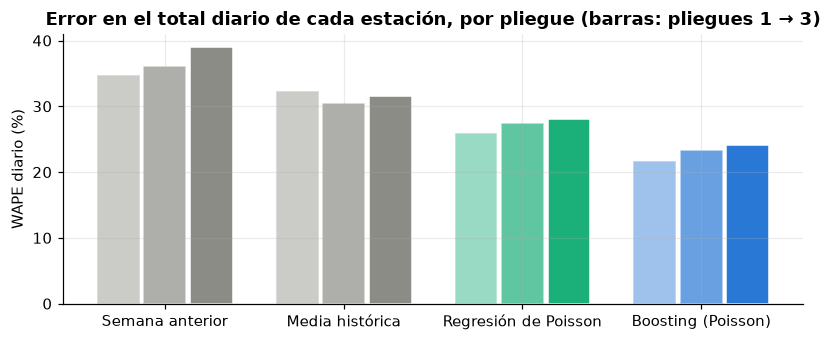

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
orden = ["Semana anterior", "Media histórica", "Regresión de Poisson", "Boosting (Poisson)"]
colores = [GRAY, GRAY, AQUA, BLUE]
for i, pliegue in enumerate(sorted(cv.pliegue.unique())):
    valores = cv[cv.pliegue == pliegue].set_index("modelo").loc[orden, "WAPE diario %"]
    ax.bar(np.arange(len(orden)) + (i - 1) * 0.26, valores, width=0.24, color=colores,
           alpha=[0.45, 0.7, 1.0][i], edgecolor="white", linewidth=1)
ax.set_xticks(np.arange(len(orden)), orden)
ax.set_ylabel("WAPE diario (%)")
ax.set_title("Error en el total diario de cada estación, por pliegue (barras: pliegues 1 → 3)")
plt.tight_layout()
plt.show()

**Lectura.**

- **El boosting es el mejor en los tres pliegues**, con un margen estable: devianza 1,152 ± 0,051 contra 1,233 de la regresión de Poisson y 1,269 de la media histórica. En el total diario de cada estación el error baja del 31,4 % (media histórica) al **23,0 % ± 1,3**.
- El orden de los modelos es el mismo en todos los pliegues (gráfico), así que la conclusión no depende de la época del año. Como los hiperparámetros se eligieron en otra ventana, estos números no tienen sesgo de selección.
- **Modelo seleccionado: el boosting con pérdida de Poisson**, porque tiene el menor error en todas las métricas y en los tres pliegues. Se elige acá, con la validación cruzada, y no con el test: el test queda para medir una sola vez el modelo ya elegido (sección 9).
- El **sesgo** de la media histórica cambia mucho entre pliegues (−6,8 % ± 7,3): no sabe en qué estación del año está. El boosting se mantiene cerca de cero (−0,3 % ± 2,1) porque sus rezagos de 7 y 28 días siguen el nivel reciente.

### 8.1 Tratamiento de la demanda censurada

El tercer notebook dejó planteada la pregunta: cuando una estación está **vacía** (`flag_vacia`) o **cerrada** (`sin_alquiler`), los retiros observados son menores que la demanda real. Si el modelo entrena con esas horas, aprende que "a esa hora hay poca demanda" cuando lo que hubo fue poca **oferta**.

Experimento, en el último pliegue: se compara el boosting entrenado con todas las horas contra uno entrenado **sin las horas censuradas**.

**Cuidado: este experimento selecciona por el resultado.** `flag_vacia` se mide en la **misma** hora que el target, y los retiros de esa hora son en parte los que vacían la estación: es la advertencia del tercer notebook. Sacar esas horas del entrenamiento no saca una muestra al azar, saca las horas en que la demanda agotó la oferta. Y evaluar sólo en las horas "limpias" favorece por construcción al modelo que se entrenó con ese mismo tipo de horas. Por eso se miran las dos evaluaciones: sobre todas las horas de validación y sobre las limpias.

In [13]:
censura_retiros = ((df.flag_vacia == 1) | (df.sin_alquiler == 1)).to_numpy()
sin_censura_observada = ((df.flag_vacia == 0) & (df.sin_alquiler == 0)).to_numpy()
print(f"Horas de train censuradas para retiros: {censura_retiros[es_train].mean():.1%} "
      f"(sin fotos, no se sabe: {df.sin_fotos[es_train].mean():.1%})")

boosting_sin_censura = nuevo_boosting().fit(X.loc[entr_val & ~censura_retiros], df.loc[entr_val & ~censura_retiros, "retiros"])
pred_sin_censura = boosting_sin_censura.predict(X.loc[val])

y_val = df.loc[val, "retiros"].to_numpy()
grupos_de_horas = {"Todas las horas": np.ones(val.sum(), dtype=bool),
                   "Horas limpias (con fotos, sin censura)": sin_censura_observada[val],
                   "Horas censuradas": censura_retiros[val]}
filas = []
for horas, mascara in grupos_de_horas.items():
    for modelo, pred in [("con todas las horas", pred_boosting_val), ("sin horas censuradas", pred_sin_censura)]:
        m = metricas(y_val[mascara], pred[mascara])
        filas.append({"evaluado en": horas, "entrenado": modelo, "retiros medios": y_val[mascara].mean(),
                      "predicción media": pred[mascara].mean(), "Devianza Poisson": m["Devianza Poisson"],
                      "Sesgo %": m["Sesgo %"]})
pd.DataFrame(filas).set_index(["evaluado en", "entrenado"]).round(3)

Horas de train censuradas para retiros: 10.2% (sin fotos, no se sabe: 27.2%)


retiros medios  predicción media  Devianza Poisson  Sesgo %
evaluado en                            entrenado                                                                        
Todas las horas                        con todas las horas            0.919             0.931             1.112    1.343
                                       sin horas censuradas           0.919             0.998             1.123    8.669
Horas limpias (con fotos, sin censura) con todas las horas            0.989             0.937             1.127   -5.305
                                       sin horas censuradas           0.989             0.995             1.121    0.557
Horas censuradas                       con todas las horas            0.755             1.086             1.143   43.802
                                       sin horas censuradas           0.755             1.213             1.237   60.563

**Lectura.**

- El 10,2 % de las horas de train está censurado (vacía o cerrada) y en otro 27,2 % no se sabe, porque no hay fotos.
- **Sobre todas las horas de validación gana el modelo entrenado con todas las horas:** devianza 1,112 contra 1,123, y sesgo +1,3 % contra +8,7 %.
- **Sobre las horas limpias gana el otro** (1,121 contra 1,127; sesgo +0,6 % contra −5,3 %), pero eso pasa en parte por construcción: se lo evalúa con el mismo tipo de horas con el que se lo entrenó.
- **En las horas censuradas los dos modelos predicen bastante más de lo observado:** 1,09 y 1,21 retiros por hora contra 0,76. Aun el modelo que vio esas horas espera un 44 % más. Son, en general, franjas de mucha demanda en las que la estación se quedó sin bicis. Es evidencia de demanda no atendida, aunque no se pueda medir con precisión.
- **Decisión.** El modelo principal se entrena con **todas las horas**: predice lo que el sistema va a registrar, que es lo que se puede validar de punta a punta, y es el mejor sobre la validación completa. El modelo sin horas censuradas se conserva sólo como **aproximación de la demanda latente** para la sección 12.2, sabiendo que su entrenamiento selecciona horas por el resultado. La sección 8.2 repite el experimento con una marca de censura que no depende del resultado.

### 8.2 Censura medida al inicio de la hora

La devolución del segundo entregable marcó el **tratamiento de la censura** como próximo paso. El punto débil de 8.1 es que `flag_vacia` y `sin_alquiler` se miden con las fotos de la **misma** hora que el target. Una marca que no depende del resultado es el estado de la estación **antes de que empiece la hora**:

- **`censura_al_inicio`** vale 1 si en la **última foto de la hora anterior** la estación no tenía bicis disponibles o no alquilaba (`is_renting = False`). Se conoce antes de que ocurran los retiros de la hora, así que no depende de ellos.
- Se calcula con DuckDB desde las **fotos crudas**, con los mismos descartes que el tercer notebook (el fragmento de abril de 2024 y las fotos con capacidad 0). Si la hora anterior no tiene fotos, queda sin dato, como pasa con `sin_fotos`.
- **Qué cambia respecto de 8.1:** deja de marcar las horas que **se vacían durante** la hora, que son las que más se seleccionan por el resultado, y pasa a marcar las que **arrancan vacías** aunque se repongan en el camino.

Primero se comparan las dos marcas en el train.

In [14]:
CONSULTA_CENSURA_INICIO = f'''
WITH ultima_foto AS (
    -- estado de cada estación en su última foto de cada hora, asignado a la hora SIGUIENTE
    SELECT TRY_CAST(station_id AS INTEGER) AS station_id,
           CAST(date_trunc('hour', committed_at_utc AT TIME ZONE 'America/Argentina/Buenos_Aires') AS TIMESTAMP)
               + INTERVAL 1 HOUR AS ts,
           arg_max(num_bikes_available = 0, committed_at_utc) AS vacia,
           arg_max(NOT is_renting, committed_at_utc)          AS cerrada
    FROM read_parquet('{(FOTOS_CRUDAS / "*" / "*.parquet").as_posix()}', union_by_name = true)
    WHERE capacity > 0  -- mismos descartes que el tercer notebook
      AND committed_at_utc >= TIMESTAMPTZ '2024-08-01 00:00:00-03'
    GROUP BY 1, 2
)
SELECT d.station_id, d.ts, CAST(u.vacia OR u.cerrada AS FLOAT) AS censura_al_inicio
FROM (SELECT station_id, CAST(timezone('America/Argentina/Buenos_Aires', hora_local) AS TIMESTAMP) AS ts
      FROM read_parquet('{DATASET.as_posix()}')) AS d
LEFT JOIN ultima_foto AS u USING (station_id, ts)
ORDER BY d.station_id, d.ts
'''

inicio = time.perf_counter()
marca = con.execute(CONSULTA_CENSURA_INICIO).df()
# mismo orden que df (estación, hora): se asigna por posición después de verificarlo
assert len(marca) == len(df)
assert (marca.station_id.to_numpy() == df.station_id.to_numpy()).all() and (marca.ts.to_numpy() == df.ts.to_numpy()).all()
df["censura_al_inicio"] = marca.censura_al_inicio.to_numpy(dtype="float32")
del marca
print(f"Marca calculada desde las fotos crudas en {time.perf_counter() - inicio:.0f} s")

censura_inicio_retiros = (df.censura_al_inicio == 1).to_numpy()
arranca_con_bicis = (df.censura_al_inicio == 0).to_numpy()
misma_hora = np.select([censura_retiros, sin_censura_observada], ["censurada", "sin censura"], "sin fotos")
al_inicio = np.select([censura_inicio_retiros, arranca_con_bicis], ["arranca vacía o cerrada", "arranca con bicis"], "sin foto previa")
cruce = (pd.DataFrame({"marca de 8.1 (misma hora)": misma_hora[es_train], "marca de 8.2 (inicio de la hora)": al_inicio[es_train],
                       "retiros": df.retiros.to_numpy()[es_train]})
           .groupby(["marca de 8.1 (misma hora)", "marca de 8.2 (inicio de la hora)"]).retiros.agg(["size", "mean"]))
cruce["% de las horas de train"] = 100 * cruce["size"] / es_train.sum()
cruce.drop(columns="size").rename(columns={"mean": "retiros medios"}).round(2)

Marca calculada desde las fotos crudas en 6 s


retiros medios  % de las horas de train
marca de 8.1 (misma hora) marca de 8.2 (inicio de la hora)                                         
censurada                 arranca con bicis                           1.74                     3.12
                          arranca vacía o cerrada                     0.32                     6.96
                          sin foto previa                             0.30                     0.12
sin censura               arranca con bicis                           1.00                    59.64
                          arranca vacía o cerrada                     1.25                     2.20
                          sin foto previa                             0.50                     0.72
sin fotos                 arranca con bicis                           0.59                     0.73
                          arranca vacía o cerrada                     0.20                     0.12
                          sin foto previa                             0.91                    26.39

**Lectura.**

- **Las dos marcas coinciden en la mayoría de las horas censuradas:** el 7,0 % de las horas de train está censurado con las dos (la estación arrancó vacía o cerrada y siguió así), con 0,32 retiros por hora.
- **La diferencia está en las horas que se vacían durante la hora:** el 3,1 % del train tiene la marca de 8.1 pero arrancó con bicis, y es el grupo con **más retiros** de toda la tabla: 1,74 por hora, contra 1,00 de las horas sin censura. Es la selección por el resultado que advertía 8.1: la demanda de esa hora fue la que vació la estación, y sacar esas horas del entrenamiento saca justo las de más demanda.
- Al revés, el 2,2 % del train arrancó vacío pero no queda marcado en 8.1, porque se repuso durante la hora (1,25 retiros por hora).

Se repite el experimento de 8.1 en el último pliegue: un boosting entrenado **sin las horas que arrancan vacías o cerradas**, comparado con los dos modelos de 8.1. La evaluación que no favorece a ningún modelo es la de **todas las horas**. La de las horas que **arrancan con bicis** es la que más se acerca a medir la demanda sin censura sin seleccionar por el resultado.

In [15]:
boosting_sin_censura_inicio = nuevo_boosting().fit(X.loc[entr_val & ~censura_inicio_retiros],
                                                   df.loc[entr_val & ~censura_inicio_retiros, "retiros"])
pred_sin_censura_inicio = boosting_sin_censura_inicio.predict(X.loc[val])

grupos_de_horas_inicio = {"Todas las horas": np.ones(val.sum(), dtype=bool),
                          "Arrancan con bicis": arranca_con_bicis[val],
                          "Arrancan vacías o cerradas": censura_inicio_retiros[val]}
filas = []
for horas, mascara in grupos_de_horas_inicio.items():
    for modelo, pred in [("con todas las horas", pred_boosting_val),
                         ("sin censura en la misma hora (8.1)", pred_sin_censura),
                         ("sin censura al inicio de la hora (8.2)", pred_sin_censura_inicio)]:
        m = metricas(y_val[mascara], pred[mascara])
        filas.append({"evaluado en": horas, "entrenado": modelo, "retiros medios": y_val[mascara].mean(),
                      "predicción media": pred[mascara].mean(), "Devianza Poisson": m["Devianza Poisson"],
                      "Sesgo %": m["Sesgo %"]})
experimento_censura_inicio = pd.DataFrame(filas).set_index(["evaluado en", "entrenado"])
experimento_censura_inicio.round(3)

retiros medios  predicción media  Devianza Poisson  Sesgo %
evaluado en                entrenado                                                                                          
Todas las horas            con todas las horas                              0.919             0.931             1.112    1.343
                           sin censura en la misma hora (8.1)               0.919             0.998             1.123    8.669
                           sin censura al inicio de la hora (8.2)           0.919             1.013             1.125   10.302
Arrancan con bicis         con todas las horas                              1.027             0.961             1.142   -6.462
                           sin censura en la misma hora (8.1)               1.027             1.023             1.136   -0.458
                           sin censura al inicio de la hora (8.2)           1.027             1.037             1.132    0.911
Arrancan vacías o cerradas con todas las horas                              0.537             0.985             1.088   83.497
                           sin censura en la misma hora (8.1)               0.537             1.100             1.201  104.931
                           sin censura al inicio de la hora (8.2)           0.537             1.120             1.232  108.788

**Lectura.**

- **Sobre todas las horas sigue ganando el modelo entrenado con todas las horas** (devianza 1,112 y sesgo +1,3 %), contra 1,123 y 1,125 de los dos modelos sin horas censuradas. La decisión de 8.1 no cambia: el modelo principal se entrena con todas las horas.
- **En las horas que arrancan con bicis**, que se eligen sin mirar el resultado, el modelo de 8.2 es el de menor devianza (1,132, contra 1,136 del de 8.1 y 1,142 del principal), y los dos modelos sin censura quedan casi sin sesgo (+0,9 % y −0,5 %). Un sesgo levemente positivo es lo esperable, porque algunas de esas horas se vacían en el camino. El principal subestima un 6,5 %: aprendió también de las horas en que no había bicis.
- **En las horas que arrancan vacías o cerradas**, los dos modelos sin censura predicen el doble de lo observado (1,10 y 1,12 retiros por hora contra 0,54), y aun el principal espera un 83 % más. Confirma, con una marca que no depende del resultado, que en esas horas hay demanda que no se atiende.
- **Conclusión:** la selección por el resultado de 8.1 existe (lo muestra la tabla anterior), pero casi no cambia los modelos: los dos latentes predicen parecido. Cuánto cambia la demanda perdida se mide en la sección 12.2.

## 9. Modelo final y evaluación en test

Se reentrena con **todo el train** (enero de 2024 a mayo de 2026) y se evalúa **una sola vez** en el test (junio a agosto de 2026). Siguiendo la sección 8.1, los dos modelos principales (retiros y arribos) se entrenan con **todas las horas**: predicen los viajes que el sistema va a registrar, que es lo que se puede validar. Aparte se entrena el modelo de retiros **sin horas censuradas**, que se usa sólo como aproximación de la demanda latente en la sección 12.2. El test se evalúa con **todas** sus horas.

In [16]:
inicio = time.perf_counter()
modelo_retiros = nuevo_boosting().fit(X.loc[es_train], df.loc[es_train, "retiros"])
modelo_arribos = nuevo_boosting().fit(X.loc[es_train], df.loc[es_train, "arribos"])
modelo_latente = nuevo_boosting().fit(X.loc[es_train & ~censura_retiros], df.loc[es_train & ~censura_retiros, "retiros"])
glm_retiros = entrenar_glm(es_train, "retiros")
print(f"Modelos finales entrenados en {time.perf_counter() - inicio:.0f} s")

test = df.loc[es_test].copy()
test["pred_retiros"] = modelo_retiros.predict(X.loc[es_test])
test["pred_arribos"] = modelo_arribos.predict(X.loc[es_test])
test["pred_latente"] = modelo_latente.predict(X.loc[es_test])
test["pred_glm"] = glm_retiros.predict(test[COLUMNAS_GLM])
bases_retiros = predecir_baselines(es_train, es_test, "retiros")
bases_arribos = predecir_baselines(es_train, es_test, "arribos")
test["base_retiros"] = bases_retiros["Media histórica estación × hora × tipo de día"]
test["base_arribos"] = bases_arribos["Media histórica estación × hora × tipo de día"]

resultados_test = {
    "retiros": evaluar(test, test.retiros, {**bases_retiros,
                                             "Regresión de Poisson": test.pred_glm,
                                             "Boosting (Poisson)": test.pred_retiros}),
    "arribos": evaluar(test, test.arribos, {**bases_arribos, "Boosting (Poisson)": test.pred_arribos}),
}
pd.concat(resultados_test, names=["target", "modelo"]).round(3)

Modelos finales entrenados en 1031 s


Devianza Poisson   RMSE    MAE     R²    RAE  Sesgo %  MAE diario  WAPE diario %
target  modelo                                                                                                                         
retiros Cero                                                     18.218  1.439  0.665 -0.271  0.756 -100.000      15.943        100.000
        Semana anterior                                           7.602  1.385  0.734 -0.178  0.836   -1.595       7.323         45.933
        Promedio 7 días, misma hora                               1.801  1.120  0.681  0.229  0.776   -1.054       7.630         47.855
        Media histórica estación × hora × tipo de día             1.157  1.131  0.734  0.215  0.835   41.526       8.301         52.065
        Regresión de Poisson                                      1.068  1.030  0.641  0.348  0.730   -1.073       5.309         33.302
        Boosting (Poisson)                                        1.009  0.998  0.607  0.389  0.691    0.378       4.630         29.040
arribos Cero                                                     18.193  1.427  0.665 -0.277  0.762 -100.000      15.942        100.000
        Semana anterior                                           7.384  1.345  0.718 -0.135  0.823   -1.598       7.296         45.765
        Promedio 7 días, misma hora                               1.780  1.092  0.670  0.252  0.768   -1.054       7.654         48.009
        Media histórica estación × hora × tipo de día             1.129  1.101  0.721  0.240  0.827   41.442       8.272         51.889
        Boosting (Poisson)                                        0.979  0.967  0.596  0.414  0.683    1.062       4.608         28.902

**Lectura.**

- **El boosting es el mejor modelo en test para los dos targets.**
  - Retiros: devianza 1,009 contra 1,068 de la regresión de Poisson y 1,157 de la media histórica; WAPE diario 29,0 % contra 33,3 % y 52,1 %; sesgo +0,4 %.
  - Arribos: devianza 0,979, WAPE diario 28,9 % y sesgo +1,1 %.
- **La media histórica se desploma en test (sesgo +41,5 %).** El test es **invierno**, y la demanda cae fuerte en invierno: 0,66 retiros por estación y hora en el test contra 0,95 de promedio en el train (en junio y julio de 2025 había bajado a 0,52–0,59). La media histórica no conoce la estación del año; el boosting la sigue con los rezagos de 7 y 28 días. Por eso en test hasta copiar la semana anterior le gana en WAPE diario a la media histórica, cosa que no pasaba en la validación.
- **El error en test (WAPE 29 %) es mayor que en la validación cruzada (23 %)** porque con menos viajes el ruido propio de un conteo pesa más en términos relativos. Pasa lo mismo en la ventana de búsqueda, que también es invierno (34 %, con menos datos de entrenamiento).
- **R² = 0,39 por hora es esperable.** Con una media de 0,66 retiros por hora, aunque el modelo conociera la media exacta, el resultado de cada hora sigue siendo aleatorio (en una Poisson la varianza es igual a la media). Las decisiones se toman sobre totales por franja o por día, donde el error relativo es mucho menor.

### 9.1 Modelo principal y modelo latente, por tipo de hora

Se comparan en test el modelo principal (todas las horas) y el entrenado sin horas censuradas, separando las horas según lo que se sabe de la estación.

In [17]:
tipos_de_hora = {
    "Todo el test": np.ones(len(test), dtype=bool),
    "Con bicis (sin censura, con fotos)": sin_censura_observada[es_test],
    "Censuradas (vacía o cerrada)": censura_retiros[es_test],
    "Sin fotos (no se sabe)": test.sin_fotos.eq(1).to_numpy(),
}
filas = []
for tipo, mascara in tipos_de_hora.items():
    sub = test[mascara]
    for modelo, columna in [("principal (todas las horas)", "pred_retiros"), ("latente (sin horas censuradas)", "pred_latente")]:
        filas.append({"horas": tipo, "modelo": modelo, "filas": len(sub), "retiros medios": sub.retiros.mean(),
                      "predicción media": sub[columna].mean(),
                      "sesgo %": 100 * (sub[columna].sum() / sub.retiros.sum() - 1),
                      "devianza": mean_poisson_deviance(sub.retiros, sub[columna])})
pd.DataFrame(filas).set_index(["horas", "modelo"]).round(3)

filas  retiros medios  predicción media  sesgo %  devianza
horas                              modelo                                                                                     
Todo el test                       principal (todas las horas)     870753           0.665             0.667    0.378     1.009
                                   latente (sin horas censuradas)  870753           0.665             0.704    5.959     1.014
Con bicis (sin censura, con fotos) principal (todas las horas)     513534           0.763             0.722   -5.310     1.050
                                   latente (sin horas censuradas)  513534           0.763             0.758   -0.588     1.046
Censuradas (vacía o cerrada)       principal (todas las horas)      82222           0.482             0.758   57.130     1.021
                                   latente (sin horas censuradas)   82222           0.482             0.834   73.003     1.086
Sin fotos (no se sabe)             principal (todas las horas)     274997           0.536             0.537    0.221     0.929
                                   latente (sin horas censuradas)  274997           0.536             0.565    5.315     0.933

**Lectura.**

- **El modelo principal no tiene sesgo en el total** (+0,4 %), pero no porque acierte en cada tipo de hora:
  - donde la estación tenía bicis **subestima un 5,3 %**;
  - en las horas censuradas **sobreestima un 57 %**.

  Los dos errores se compensan. Es exactamente lo que se espera de un modelo que aprende los viajes registrados, con la censura incluida.
- **El modelo latente casi no tiene sesgo donde había bicis** (−0,6 %). Donde la estación estaba vacía predice un 73 % más de lo observado: esa diferencia es su estimación de la demanda que no se pudo atender.
- **Son dos preguntas distintas.** Para *cuántos viajes va a registrar el sistema* (el rebalanceo) se usa el modelo principal. Para *cuánta gente quiere usar la estación* (la ampliación) se usa el latente, como aproximación. Se guardan los dos (sección 13).

## 10. Análisis de los resultados

### 10.1 La red completa, hora por hora

Suma de las predicciones de todas las estaciones contra los retiros observados, en dos semanas del test.

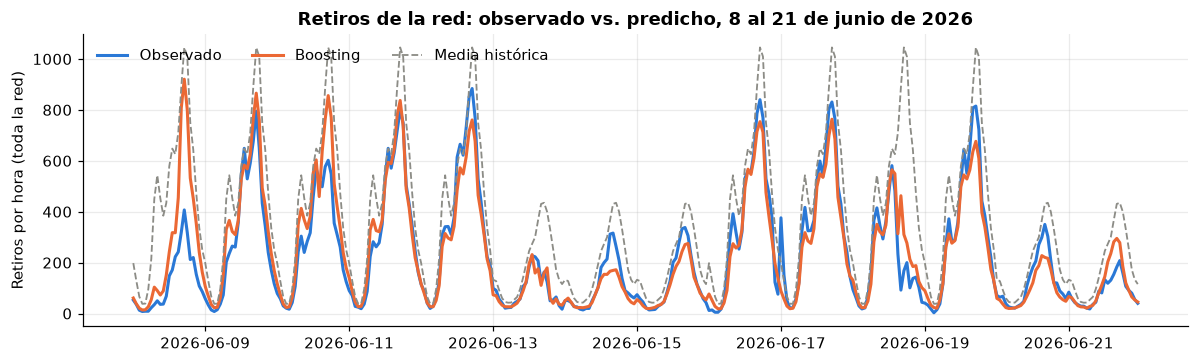

Correlación horaria de la red: boosting 0.941 · media histórica 0.895


In [18]:
red = test.groupby("ts")[["retiros", "pred_retiros", "base_retiros"]].sum()
ventana = red.loc["2026-06-08":"2026-06-21"]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(ventana.index, ventana.retiros, color=BLUE, lw=2, label="Observado")
ax.plot(ventana.index, ventana.pred_retiros, color=ORANGE, lw=2, label="Boosting")
ax.plot(ventana.index, ventana.base_retiros, color=GRAY, lw=1.2, ls="--", label="Media histórica")
ax.set_ylabel("Retiros por hora (toda la red)")
ax.set_title("Retiros de la red: observado vs. predicho, 8 al 21 de junio de 2026")
ax.legend(loc="upper left", ncols=3, frameon=False)
plt.tight_layout()
plt.show()
print(f"Correlación horaria de la red: boosting {red.retiros.corr(red.pred_retiros):.3f} · "
      f"media histórica {red.retiros.corr(red.base_retiros):.3f}")

**Lectura.**

- A nivel de toda la red el modelo sigue muy bien la forma de cada día (correlación horaria 0,94 contra 0,90 de la media histórica): los dos picos de los días hábiles y la curva única de los fines de semana.
- **El lunes 15/06 fue feriado** (Güemes, trasladado), y el modelo lo predice correctamente como un día de demanda baja.
- **Los errores grandes se concentran en tardes puntuales:** el lunes 8/06 y el viernes 19/06 se registraron muchos menos viajes que los predichos. El modelo no tiene cómo anticiparlo con estas variables. No se verificó la causa (clima de último momento, eventos, cortes).
- La media histórica exagera todos los picos, por el efecto invierno de la sección anterior.

### 10.2 Perfil por hora y sesgo por mes

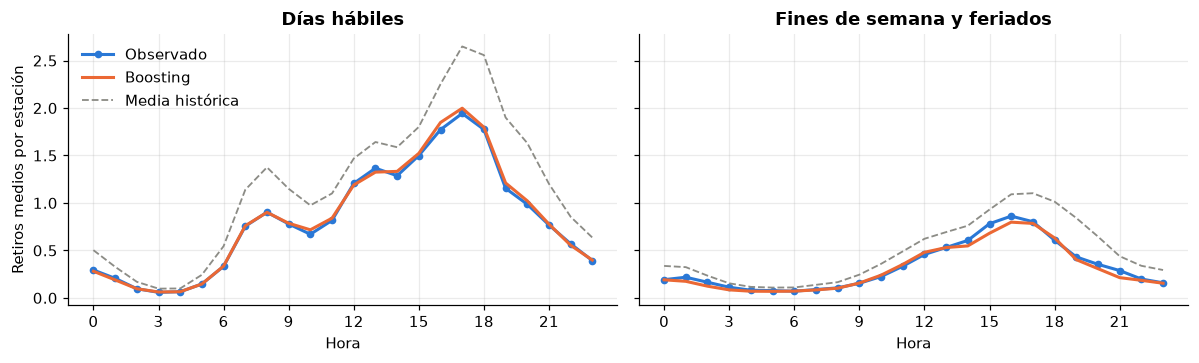

,retiros reales,predichos boosting,sesgo boosting %,sesgo media histórica %,devianza boosting
mes_nombre,,,,,
junio,193254.0,192640.23,-0.32,40.80,0.99
julio,183836.0,185607.33,0.96,50.52,1.03
agosto,201591.0,202618.40,0.51,34.03,1.01


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (habil, titulo) in zip(axes, [(1, "Días hábiles"), (0, "Fines de semana y feriados")]):
    perfil = test[test.dia_habil == habil].groupby("hora")[["retiros", "pred_retiros", "base_retiros"]].mean()
    ax.plot(perfil.index, perfil.retiros, color=BLUE, lw=2, marker="o", ms=4, label="Observado")
    ax.plot(perfil.index, perfil.pred_retiros, color=ORANGE, lw=2, label="Boosting")
    ax.plot(perfil.index, perfil.base_retiros, color=GRAY, lw=1.2, ls="--", label="Media histórica")
    ax.set_title(titulo)
    ax.set_xlabel("Hora")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("Retiros medios por estación")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

test["mes_nombre"] = test.ts.dt.month.map({6: "junio", 7: "julio", 8: "agosto"})
(test.groupby("mes_nombre", sort=False)
     .apply(lambda g: pd.Series({"retiros reales": g.retiros.sum(), "predichos boosting": g.pred_retiros.sum(),
                                 "sesgo boosting %": 100 * (g.pred_retiros.sum() / g.retiros.sum() - 1),
                                 "sesgo media histórica %": 100 * (g.base_retiros.sum() / g.retiros.sum() - 1),
                                 "devianza boosting": mean_poisson_deviance(g.retiros, g.pred_retiros)}),
            include_groups=False)
     .round(2))

**Lectura.**

- **Días hábiles:** el modelo reproduce casi exactamente el perfil medio, con los picos de las 8 h y de las 17 h.
- **Fines de semana y feriados:** también ajusta bien, apenas por debajo en el pico de la tarde.
- **Por mes**, el sesgo del boosting está entre −0,3 % y +1,0 %, mientras que el de la media histórica va del +34 % al +51 %.
- Julio es el mes de menos demanda y coincide con las vacaciones de invierno; es justo el mes en que más falla la media histórica.

### 10.3 Calibración

Se agrupan las estación-hora del test en 20 grupos según la predicción y se compara la media predicha con la observada. Un modelo calibrado queda sobre la diagonal: si dice "2 retiros", en promedio hay 2.

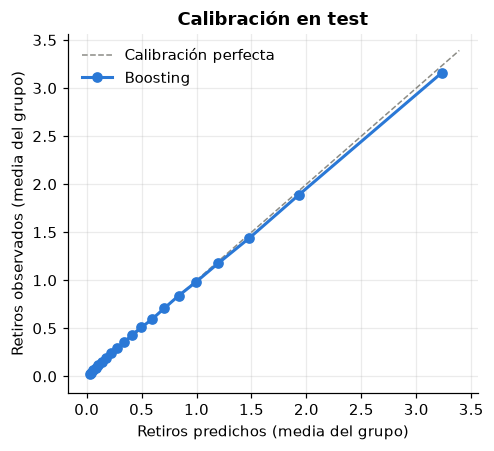

In [20]:
grupos = pd.qcut(test.pred_retiros, 20, duplicates="drop")
calibracion = test.groupby(grupos, observed=True)[["pred_retiros", "retiros"]].mean()

fig, ax = plt.subplots(figsize=(4.6, 4.2))
limite = calibracion.max().max() * 1.05
ax.plot([0, limite], [0, limite], color=GRAY, lw=1, ls="--", label="Calibración perfecta")
ax.plot(calibracion.pred_retiros, calibracion.retiros, color=BLUE, lw=2, marker="o", ms=6, label="Boosting")
ax.set_xlabel("Retiros predichos (media del grupo)")
ax.set_ylabel("Retiros observados (media del grupo)")
ax.set_title("Calibración en test")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura.** El modelo está **bien calibrado en todo el rango**: los 20 grupos quedan prácticamente sobre la diagonal, desde las horas casi sin viajes hasta las de más de 3 retiros por hora. En el grupo más alto predice apenas más de lo observado (3,25 contra 3,15). Son las horas pico de las estaciones más usadas, donde la estación a veces se vacía.

### 10.4 Importancia de las variables

Importancia por **permutación** sobre una muestra del test: cuánto empeora la devianza si se mezclan al azar los valores de una variable. A diferencia de la importancia por ganancia de los árboles, se mide sobre datos no vistos y no favorece a las variables con muchos valores distintos.

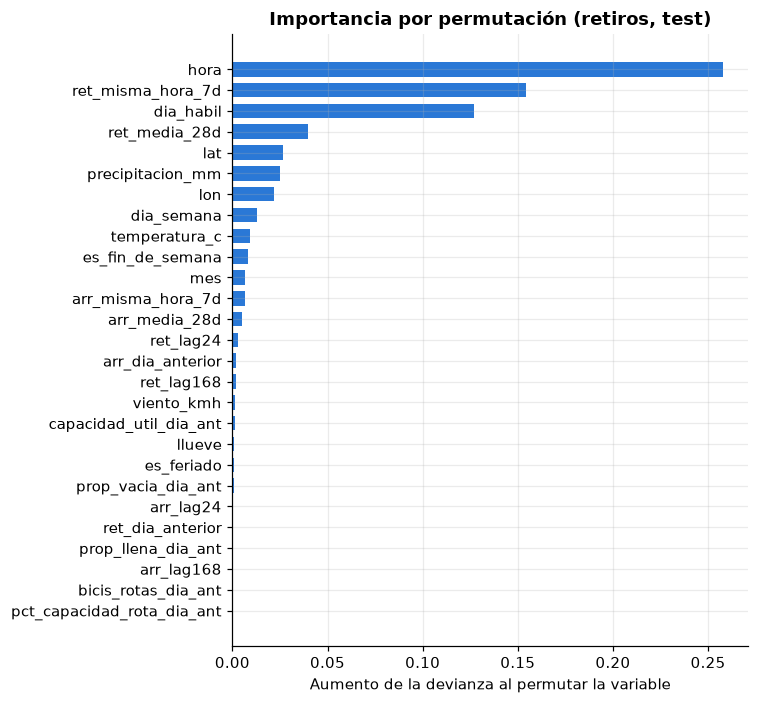

In [21]:
muestra = test.sample(300_000, random_state=SEMILLA)
importancia = permutation_importance(modelo_retiros, muestra[VARIABLES], muestra.retiros,
                                     scoring="neg_mean_poisson_deviance", n_repeats=3,
                                     random_state=SEMILLA, n_jobs=1)
importancia = pd.Series(importancia.importances_mean, index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(importancia.index, importancia.values, color=BLUE, height=0.7)
ax.set_xlabel("Aumento de la devianza al permutar la variable")
ax.set_title("Importancia por permutación (retiros, test)")
plt.tight_layout()
plt.show()

**Lectura.**

- **La hora es por lejos la variable más importante.** Le siguen el promedio de la **misma hora en la última semana** y si es **día hábil**. Después vienen el **nivel de la estación** (`ret_media_28d`), la **ubicación** y la **lluvia**.
- **Los rezagos puntuales** (`ret_lag24`, `ret_lag168`) importan poco: el promedio de 7 días contiene la misma información con menos ruido. Lo mismo pasa con `llueve` frente a `precipitacion_mm`. Con variables correlacionadas, la permutación reparte la importancia entre ellas (al mezclar una, la otra la sigue cubriendo).
- **`mes` pesa poco** porque la estacionalidad ya entra por los rezagos.
- **Las variables de estado de la estación (fotos) no aportan.** Puede que su información ya esté en los rezagos de demanda, o que el promedio del día anterior sea demasiado grueso, porque lo que vacía una estación pasa hora a hora. Para un horizonte más corto (la hora siguiente) probablemente sí servirían. La sección 10.6 verifica que esto no se debe a la mala cobertura de fotos del test.

### 10.5 Error por estación

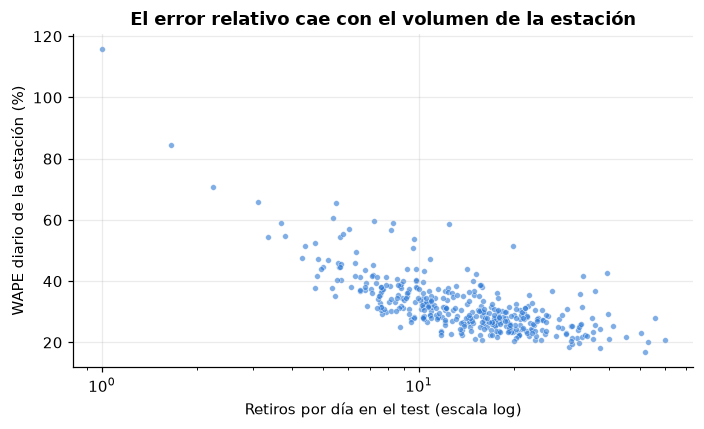

Estaciones con más de 20 retiros por día, peor error relativo:


,retiros_por_dia,pred_por_dia,mae_diario,wape_%,nombre
station_id,,,,,
515,39.2,38.1,16.8,42.8,294 - PLAZOLETA RÍO DE LA PLATA
379,33.0,32.6,13.8,41.7,390 - De Los Ombues
156,26.3,25.2,9.7,36.9,156 - Plaza Alemania
152,36.0,34.1,13.3,36.8,152 - JULIETA LANTERI
161,32.3,31.0,11.6,35.9,161 - Humahuaca
177,22.3,22.0,8.0,35.6,177 -PLANETARIO
281,22.8,22.6,7.5,32.7,350 - Plaza Irlanda
137,20.2,20.6,6.6,32.6,137 - AZOPARDO Y CHILE


In [22]:
estaciones = pd.read_csv(PROCESSED_DIR / "estaciones.csv").set_index("station_id")
diario = (test.assign(fecha=test.ts.dt.floor("D"))
              .groupby(["station_id", "fecha"])[["retiros", "pred_retiros"]].sum())
por_estacion = (diario.assign(error=(diario.pred_retiros - diario.retiros).abs())
                      .groupby("station_id")
                      .agg(retiros_por_dia=("retiros", "mean"), pred_por_dia=("pred_retiros", "mean"),
                           mae_diario=("error", "mean")))
por_estacion["wape_%"] = 100 * por_estacion.mae_diario / por_estacion.retiros_por_dia.replace(0, np.nan)
por_estacion = por_estacion.join(estaciones.nombre)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(por_estacion.retiros_por_dia, por_estacion["wape_%"], s=14, color=BLUE, alpha=0.6, edgecolor="white", lw=0.4)
ax.set_xscale("log")
ax.set_xlabel("Retiros por día en el test (escala log)")
ax.set_ylabel("WAPE diario de la estación (%)")
ax.set_title("El error relativo cae con el volumen de la estación")
plt.tight_layout()
plt.show()
print("Estaciones con más de 20 retiros por día, peor error relativo:")
por_estacion[por_estacion.retiros_por_dia > 20].sort_values("wape_%", ascending=False).head(8).round(1)

**Lectura.**

- El error relativo **cae con el volumen**: más del 50 % en estaciones con menos de 5 retiros por día y entre 20 y 30 % en las de más de 20. Es lo esperable con conteos: el ruido relativo de una Poisson baja como $1/\sqrt{n}$.
- **Entre las estaciones de mucho uso, las peores son recreativas:**
  - Plazoleta Río de la Plata (Costanera);
  - De los Ombúes, Plaza Alemania, Planetario y Plaza Irlanda (parques);
  - Julieta Lanteri (Costanera Sur).

  Su demanda depende del fin de semana, del sol y de eventos, y es mucho más volátil que la de las estaciones de viaje al trabajo.

### 10.6 Aporte de las variables de estado con buena cobertura de fotos

**Devolución del segundo entregable:** *"el período de test (junio a agosto de 2026) coincide con la degradación de las fotos (...) convendría evaluar también sobre un período con buena cobertura para medir su aporte real"*.

Las variables de estado son promedios del **día anterior**, así que en el test casi no faltan: alcanza con una foto en esas 24 horas (sección 2). Lo que sí empeora es su **calidad**: en el test se calculan con muchas menos fotos por hora, y con menos fotos la fracción del tiempo que la estación estuvo vacía o llena es más ruidosa. La conclusión de 10.4 (que no aportan) se midió justo en ese período.

Primero, la cobertura de fotos por mes y en cada período de evaluación.

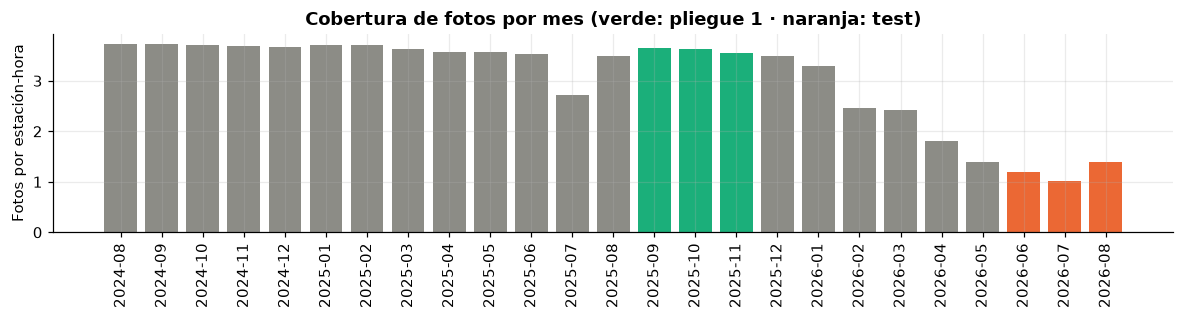

,% estación-horas con fotos,fotos por estación-hora,% faltantes de las variables de estado
período,,,
sep–nov 2025 (pliegue 1),98.55,3.61,1.40
mar–may 2026 (pliegue 3),93.88,1.88,0.84
jun–ago 2026 (test),68.42,1.21,0.18


In [23]:
cobertura = con.execute(f'''
    SELECT date_trunc('month', CAST(timezone('America/Argentina/Buenos_Aires', hora_local) AS TIMESTAMP)) AS mes,
           count(*) AS filas, count(n_fotos) AS filas_con_fotos, sum(n_fotos) AS fotos
    FROM read_parquet('{DATASET.as_posix()}')
    WHERE CAST(hora_local AS TIMESTAMPTZ) >= TIMESTAMPTZ '2024-08-01 00:00:00-03'  -- antes no hay fotos (hueco del scraper)
    GROUP BY 1 ORDER BY 1
''').df()
cobertura["fotos por estación-hora"] = cobertura.fotos / cobertura.filas_con_fotos
cobertura["% estación-horas con fotos"] = 100 * cobertura.filas_con_fotos / cobertura.filas

PERIODOS_COBERTURA = {
    "sep–nov 2025 (pliegue 1)": PLIEGUES[0],
    "mar–may 2026 (pliegue 3)": PLIEGUES[2],
    "jun–ago 2026 (test)": (TEST_DESDE, df.ts.max() + pd.Timedelta(hours=1)),
}
colores_mes = np.where(cobertura.mes >= TEST_DESDE, ORANGE,
                       np.where((cobertura.mes >= PLIEGUES[0][0]) & (cobertura.mes < PLIEGUES[0][1]), AQUA, GRAY))
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(cobertura.mes.dt.strftime("%Y-%m"), cobertura["fotos por estación-hora"], color=colores_mes)
ax.set_ylabel("Fotos por estación-hora")
ax.set_title("Cobertura de fotos por mes (verde: pliegue 1 · naranja: test)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

filas = []
for nombre, (desde, hasta) in PERIODOS_COBERTURA.items():
    meses = cobertura[(cobertura.mes >= desde) & (cobertura.mes < hasta)]
    en_periodo = ((df.ts >= desde) & (df.ts < hasta)).to_numpy()
    filas.append({"período": nombre,
                  "% estación-horas con fotos": 100 * meses.filas_con_fotos.sum() / meses.filas.sum(),
                  "fotos por estación-hora": meses.fotos.sum() / meses.filas_con_fotos.sum(),
                  "% faltantes de las variables de estado": 100 * df.loc[en_periodo, ESTADO[0]].isna().mean()})
pd.DataFrame(filas).set_index("período").round(2)

**Experimento (ablación).** Se entrena el mismo boosting, con los mismos hiperparámetros, **sin las 5 variables de estado**, y se compara con el modelo completo en los tres períodos de la tabla. Cada modelo se entrena con todo lo anterior al período, como en la sección 8. Para los dos pliegues, el modelo completo es el de la validación cruzada; para el test, el modelo final de la sección 9.

Se usa la ablación y no la importancia por permutación de 10.4 porque las cinco variables están correlacionadas entre sí: al permutar una, las otras siguen cubriendo su información. Sacarlas juntas mide su aporte **conjunto**.

**Criterio:** si las variables de estado tienen información real, sacarlas tiene que empeorar el modelo **en el período con buena cobertura**, aunque en el test no se note.

In [24]:
SIN_ESTADO = [v for v in VARIABLES if v not in ESTADO]
evaluaciones_ablacion = {
    "sep–nov 2025 (pliegue 1)": (*particion(*PLIEGUES[0]), pred_boosting_pliegues[1]),
    "mar–may 2026 (pliegue 3)": (*particion(*PLIEGUES[2]), pred_boosting_pliegues[3]),
    "jun–ago 2026 (test)": (es_train, es_test, test.pred_retiros.to_numpy()),
}
tablas = {}
for periodo, (entrenamiento, validacion, pred_completo) in evaluaciones_ablacion.items():
    inicio = time.perf_counter()
    sin_estado = nuevo_boosting().fit(df.loc[entrenamiento, SIN_ESTADO], df.loc[entrenamiento, "retiros"])
    datos = df.loc[validacion]
    tablas[periodo] = evaluar(datos, datos.retiros, {"con variables de estado": pred_completo,
                                                     "sin variables de estado": sin_estado.predict(datos[SIN_ESTADO])})
    print(f"{periodo}: {time.perf_counter() - inicio:.0f} s")

ablacion = pd.concat(tablas, names=["período", "modelo"])[["Devianza Poisson", "RMSE", "MAE", "WAPE diario %", "Sesgo %"]]
diferencia_ablacion = (ablacion.xs("sin variables de estado", level="modelo")
                       - ablacion.xs("con variables de estado", level="modelo"))
display(ablacion.round(3))
print("Diferencia (sin − con): un valor positivo en devianza o WAPE significa que sacarlas empeora el modelo")
diferencia_ablacion.round(4)

sep–nov 2025 (pliegue 1): 232 s


mar–may 2026 (pliegue 3): 273 s


jun–ago 2026 (test): 588 s


Devianza Poisson   RMSE    MAE  WAPE diario %  Sesgo %
período                  modelo                                                                         
sep–nov 2025 (pliegue 1) con variables de estado             1.133  1.271  0.794         21.641    0.383
                         sin variables de estado             1.134  1.271  0.795         21.746    0.585
mar–may 2026 (pliegue 3) con variables de estado             1.112  1.172  0.741         24.060    1.343
                         sin variables de estado             1.111  1.172  0.744         24.184    3.204
jun–ago 2026 (test)      con variables de estado             1.009  0.998  0.607         29.040    0.378
                         sin variables de estado             1.010  0.998  0.608         29.175    1.453

Diferencia (sin − con): un valor positivo en devianza o WAPE significa que sacarlas empeora el modelo


,Devianza Poisson,RMSE,MAE,WAPE diario %,Sesgo %
período,,,,,
sep–nov 2025 (pliegue 1),0.0007,-0.0003,0.0005,0.1046,0.2026
mar–may 2026 (pliegue 3),-0.0009,-0.0002,0.0024,0.1242,1.8610
jun–ago 2026 (test),0.0010,0.0008,0.0015,0.1354,1.0757


**Lectura.**

- **La cobertura de fotos del test es mucho peor:** 1,2 fotos por estación-hora y 68 % de las estación-horas con fotos, contra 3,6 y 99 % en septiembre–noviembre de 2025. Aun así, las variables de estado casi no faltan en ningún período (menos del 1,5 %), porque son promedios del día anterior.
- **Con buena cobertura tampoco aportan.** En septiembre–noviembre de 2025, sacarlas sube la devianza en 0,0007 (de 1,133 a 1,134) y el WAPE diario en 0,1 puntos (de 21,6 % a 21,7 %). Es unas 70 veces menos que la variación de la devianza entre pliegues (± 0,05, sección 8). En marzo–mayo y en el test la diferencia es del mismo tamaño.
- **La conclusión de 10.4 se confirma: no era un efecto de la degradación de las fotos.** Con un horizonte de 24 horas, lo que dicen las fotos del día anterior probablemente ya está en los rezagos de demanda: una estación que ayer se vació es una estación que ayer tuvo mucha demanda.
- Lo único que se repite en los tres períodos es que **con las variables de estado el sesgo es algo menor** (de 0,2 a 1,9 puntos) y el WAPE diario apenas mejor (0,1 puntos).
- **Decisión:** se mantienen en el modelo, porque no perjudican y bajan algo el sesgo. Para producción el resultado tiene una lectura práctica: si el feed de fotos sigue degradándose, el modelo rinde prácticamente igual sin estas variables. Donde sí podrían aportar es con un horizonte de una hora (mejora 7 de la sección 14).

### 10.7 Clima pronosticado en lugar del observado

El modelo se entrenó y se evaluó con el clima **observado** (Open-Meteo, primer notebook), pero al cierre del día anterior sólo se conoce el **pronóstico**. La devolución del segundo entregable lo marcó como próximo paso, y era la primera limitación de la sección 14. Acá se mide cuánto cuesta.

**Clima disponible al cierre del día anterior.** El repositorio de las fotos guarda cada versión de los pronósticos horarios con su hora de publicación (`committed_at_utc`). Para cada hora del test se toma la **última versión publicada antes de las 00:00 del día a predecir**, que es lo que tendría el equipo de logística al planificar.

- Las horas que todavía no tienen pronóstico a esa hora de corte se completan con el **último valor pronosticado disponible** (persistencia), y se informan aparte.
- Las unidades son las mismas que las del clima observado (°C, mm y km/h, primer notebook). `llueve` se recalcula como en el tercer notebook: precipitación mayor a 0.

In [25]:
CONSULTA_PRONOSTICO = f'''
WITH versiones AS (
    SELECT CAST(forecast_at_utc AT TIME ZONE 'America/Argentina/Buenos_Aires' AS TIMESTAMP)  AS ts,
           CAST(committed_at_utc AT TIME ZONE 'America/Argentina/Buenos_Aires' AS TIMESTAMP) AS publicado,
           temperature, rain, wind_speed
    FROM read_parquet('{(PRONOSTICOS / "*" / "*.parquet").as_posix()}', union_by_name = true)
)
SELECT ts,
       arg_max(temperature, publicado) AS temperatura_c,
       arg_max(rain, publicado)        AS precipitacion_mm,
       arg_max(wind_speed, publicado)  AS viento_kmh
FROM versiones
WHERE publicado < date_trunc('day', ts)  -- sólo lo publicado antes de las 00:00 del día a predecir
GROUP BY ts
'''
COLUMNAS_CLIMA = ["temperatura_c", "precipitacion_mm", "viento_kmh"]

# grilla horaria desde el día anterior al test, para poder completar las primeras horas
horas_test = pd.DataFrame({"ts": pd.date_range(TEST_DESDE - pd.Timedelta(days=1), test.ts.max(), freq="h")})
pronostico = horas_test.merge(con.execute(CONSULTA_PRONOSTICO).df(), on="ts", how="left")
pronostico["pronosticada"] = pronostico.temperatura_c.notna()
pronostico[COLUMNAS_CLIMA] = pronostico[COLUMNAS_CLIMA].ffill()  # último valor pronosticado disponible
pronostico["llueve"] = (pronostico.precipitacion_mm > 0).astype("int8")
pronostico = pronostico[pronostico.ts >= TEST_DESDE].set_index("ts")

por_hora = pronostico.groupby(pronostico.index.hour).pronosticada.mean()
print(f"Horas del test con pronóstico publicado antes de las 00:00: {pronostico.pronosticada.mean():.1%}")
print(f"  de 0 a 20 h: {por_hora.loc[0:20].mean():.1%} · de 21 a 23 h: {por_hora.loc[21:23].mean():.1%}")

observado = test.groupby("ts")[CLIMA].first()  # el clima es el mismo para todas las estaciones
previsto = pronostico.reindex(observado.index)
reales = previsto.pronosticada.to_numpy()  # la comparación se hace sólo en las horas con pronóstico
print(f"Horas con lluvia (con pronóstico): observadas {observado.llueve[reales].sum()} · "
      f"pronosticadas {previsto.llueve[reales].sum()} · en ambas {(observado.llueve & previsto.llueve)[reales].sum()}")
pd.DataFrame({
    variable: {"media observada": observado[variable][reales].mean(),
               "media pronosticada": previsto[variable][reales].mean(),
               "correlación": observado[variable][reales].corr(previsto[variable][reales]),
               "error absoluto medio": (observado[variable] - previsto[variable])[reales].abs().mean()}
    for variable in COLUMNAS_CLIMA}).round(3)

Horas del test con pronóstico publicado antes de las 00:00: 83.7%
  de 0 a 20 h: 95.7% · de 21 a 23 h: 0.0%
Horas con lluvia (con pronóstico): observadas 184 · pronosticadas 143 · en ambas 99


,temperatura_c,precipitacion_mm,viento_kmh
media observada,11.155,0.089,9.893
media pronosticada,11.075,0.040,9.909
correlación,0.977,0.217,0.841
error absoluto medio,0.548,0.089,1.531


**Lectura.**

- **Hay pronóstico para el 84 % de las horas del test:** el 96 % de las horas de 0 a 20 h y ninguna de 21 a 23 h, porque las versiones publicadas antes de medianoche todavía no llegan a esas tres horas. El resto de las horas de 0 a 20 h sin pronóstico son de días en que no hubo publicaciones antes de medianoche.
- **Temperatura y viento se pronostican bien:** correlación 0,98 y 0,84, con un error medio de 0,5 °C y 1,5 km/h.
- **La lluvia es el punto débil.** El pronóstico acierta 99 de las 184 horas con lluvia (54 %), anuncia lluvia en 44 horas en las que no llovió y, en promedio, pronostica menos de la mitad de los milímetros. Y la lluvia es la variable de clima que más pesa en el modelo (sección 10.4).

**Experimento.** Los modelos finales de la sección 9, **sin reentrenar**, predicen el test con el clima pronosticado en lugar del observado. La diferencia es el costo de usarlos en producción con el clima que realmente va a estar disponible.

In [26]:
X_pronostico = test[VARIABLES].copy()
X_pronostico[CLIMA] = pronostico[CLIMA].reindex(test.ts).to_numpy()
test["pred_retiros_pronostico"] = modelo_retiros.predict(X_pronostico)
pred_arribos_pronostico = modelo_arribos.predict(X_pronostico)
del X_pronostico

display(pd.concat({
    "retiros": evaluar(test, test.retiros, {"clima observado": test.pred_retiros,
                                            "clima pronosticado": test.pred_retiros_pronostico}),
    "arribos": evaluar(test, test.arribos, {"clima observado": test.pred_arribos,
                                            "clima pronosticado": pred_arribos_pronostico}),
}, names=["target", "clima"])[["Devianza Poisson", "RMSE", "MAE", "Sesgo %", "WAPE diario %"]].round(3))

pronosticada = pronostico.pronosticada.reindex(test.ts).to_numpy()
llovio = (test.precipitacion_mm > 0).to_numpy()
grupos_clima = {"Horas con pronóstico": pronosticada, "Horas completadas": ~pronosticada,
                "Horas con lluvia observada": llovio, "Horas sin lluvia observada": ~llovio}
filas = []
for horas, mascara in grupos_clima.items():
    for clima, columna in [("observado", "pred_retiros"), ("pronosticado", "pred_retiros_pronostico")]:
        m = metricas(test.retiros[mascara], test[columna][mascara])
        filas.append({"horas": horas, "clima": clima, "filas": mascara.sum(), "retiros medios": test.retiros[mascara].mean(),
                      "predicción media": test[columna][mascara].mean(), "Devianza Poisson": m["Devianza Poisson"],
                      "Sesgo %": m["Sesgo %"]})
costo_pronostico = pd.DataFrame(filas).set_index(["horas", "clima"])
costo_pronostico.round(3)

Devianza Poisson   RMSE    MAE  Sesgo %  WAPE diario %
target  clima                                                                     
retiros clima observado                1.009  0.998  0.607    0.378         29.040
        clima pronosticado             1.011  0.999  0.611    1.687         29.846
arribos clima observado                0.979  0.967  0.596    1.062         28.902
        clima pronosticado             0.979  0.968  0.599    2.180         29.676

filas  retiros medios  predicción media  Devianza Poisson  Sesgo %
horas                      clima                                                                            
Horas con pronóstico       observado     729058           0.696             0.700             1.011    0.658
                           pronosticado  729058           0.696             0.707             1.011    1.568
Horas completadas          observado     141695           0.504             0.496             0.999   -1.613
                           pronosticado  141695           0.504             0.517             1.008    2.533
Horas con lluvia observada observado      87956           0.397             0.381             0.914   -4.204
                           pronosticado   87956           0.397             0.541             0.948   36.160
Horas sin lluvia observada observado     782797           0.695             0.699             1.019    0.672
                           pronosticado  782797           0.695             0.691             1.018   -0.529

**Lectura.**

- **El costo total de usar el pronóstico es chico.** En retiros, la devianza pasa de 1,009 a 1,011 y el WAPE diario de 29,0 % a 29,8 %; en arribos, el WAPE pasa de 28,9 % a 29,7 %. El boosting sigue muy por delante de los baselines (45,9 % el mejor en test). Así queda medida la limitación 1 de la sección 14, que los resultados con clima observado eran algo optimistas: menos de un punto de WAPE diario.
- **El sesgo sube** de +0,4 % a +1,7 %: el pronóstico anuncia menos lluvia de la que hubo, y el modelo espera más viajes.
- **El costo se concentra en las horas con lluvia:** ahí el modelo pasa de subestimar un 4 % a **sobreestimar un 36 %**, porque en casi la mitad de esas horas el pronóstico no anunciaba lluvia. En las horas sin lluvia casi no cambia nada (sesgo −0,5 % contra +0,7 %).
- **Las horas completadas** (21 a 23 h y días sin publicación) empeoran algo (devianza de 0,999 a 1,008), mientras que en las pronosticadas la devianza no cambia (1,011). Son horas de menos demanda.
- **Implicancia para producción:** en los días de lluvia la predicción del día anterior es menos confiable, y conviene actualizarla durante el día con el pronóstico más reciente. El paso siguiente es **reentrenar con pronósticos** (los hay desde septiembre de 2024), para que el modelo aprenda cuánto confiar en ellos (sección 14.3).

## 11. Agrupamiento de estaciones (aprendizaje no supervisado)

Las estaciones no se usan igual: unas son **origen** a la mañana (barrios residenciales, la gente sale a trabajar) y **destino** a la tarde, y otras al revés. Para el rebalanceo importa saber **a qué hora** se vacía o se llena cada una.

**Perfil de cada estación:** para los días hábiles del último año del train (junio de 2025 a mayo de 2026), la fracción de sus movimientos diarios (retiros + arribos) que ocurre en cada hora, separada en retiros y arribos: 48 valores que suman 1. Así se compara la **forma** del día y no el volumen. Se dejan afuera las estaciones con menos de 5 movimientos por día hábil, cuyo perfil es puro ruido.

**Técnica:** *K-means*. Las variables ya están en la misma escala (proporciones), así que no se estandarizan: estandarizar inflaría el ruido de las horas de la madrugada. DBSCAN no aplica bien acá: en 48 dimensiones la densidad no separa grupos y además dejaría estaciones como "ruido", cuando cada estación necesita un grupo.

Estaciones con perfil: 404 de 405


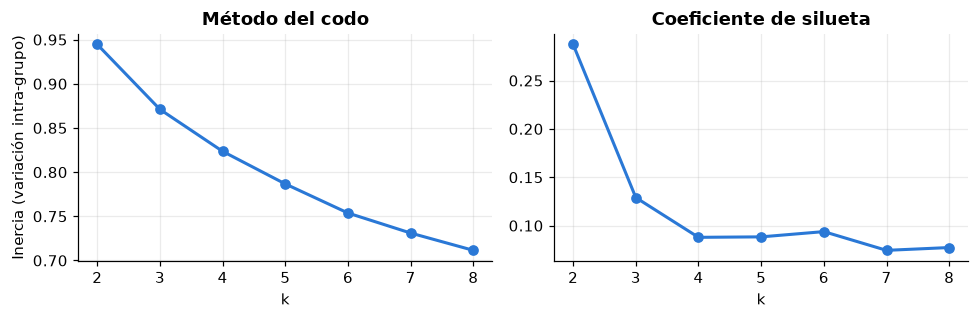

,2,3,4,5,6,7,8
inercia,0.945,0.871,0.824,0.787,0.754,0.731,0.711
silueta,0.287,0.129,0.088,0.088,0.094,0.074,0.077


In [27]:
ultimo_anio = es_train & (df.ts >= "2025-06-01").to_numpy() & (df.dia_habil == 1).to_numpy()
perfil = df.loc[ultimo_anio].groupby(["station_id", "hora"])[["retiros", "arribos"]].mean().unstack("hora")
movimientos_dia = perfil.sum(axis=1)
perfil = perfil[movimientos_dia >= 5]
forma = perfil.div(perfil.sum(axis=1), axis=0)
forma.columns = [f"{tipo}_{hora:02d}" for tipo, hora in forma.columns]
print(f"Estaciones con perfil: {len(forma)} de {len(movimientos_dia)}")

ks = range(2, 9)
modelos_k = {k: KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(forma) for k in ks}
eleccion_k = pd.DataFrame({"inercia": {k: m.inertia_ for k, m in modelos_k.items()},
                           "silueta": {k: silhouette_score(forma, m.labels_) for k, m in modelos_k.items()}})

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(eleccion_k.index, eleccion_k.inercia, color=BLUE, lw=2, marker="o", ms=6)
axes[0].set_title("Método del codo")
axes[0].set_ylabel("Inercia (variación intra-grupo)")
axes[1].plot(eleccion_k.index, eleccion_k.silueta, color=BLUE, lw=2, marker="o", ms=6)
axes[1].set_title("Coeficiente de silueta")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()
eleccion_k.round(3).T

**Lectura.**

- **La silueta es baja para todo k** (0,29 con k = 2 y entre 0,07 y 0,13 desde k = 3), y la inercia baja de forma suave, sin codo claro. Los perfiles horarios forman un **continuo**, no grupos bien separados: hay estaciones de todos los grados intermedios entre "origen a la mañana" y "destino a la mañana".
- Por eso k no se elige por la silueta (que favorece dos grupos, demasiado gruesos para operar) sino por **interpretabilidad**. Con **k = 4** aparecen cuatro patrones distintos y con sentido operativo (gráficos de abajo). El agrupamiento se usa como **segmentación descriptiva**, no como clases naturales.
- Las etiquetas de K-means son arbitrarias. Por eso los nombres de los grupos se asignan en el código a partir del flujo neto de la mañana de cada centroide, y siguen siendo correctos si se reentrena.

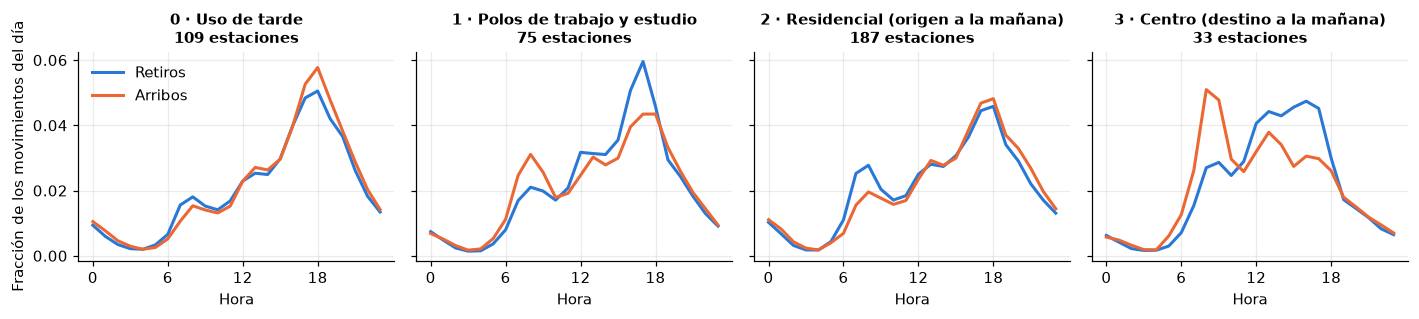

grupo,0,1,2,3
hora (flujo neto medio),,,,
7,-0.16,0.37,-0.52,0.66
8,-0.07,0.52,-0.44,1.20
9,-0.04,0.28,-0.14,0.95
17,0.16,-0.71,0.13,-0.76
18,0.27,-0.11,0.10,-0.14
19,0.21,0.15,0.13,0.02


In [28]:
K = 4  # ver la lectura anterior: se elige por interpretabilidad, no por la silueta
kmeans = modelos_k[K]
# Las etiquetas de K-means son arbitrarias: los nombres se asignan según el flujo neto de la mañana (7 a 9 h)
# de cada centroide, para que sigan siendo correctos si se reentrena con otros datos.
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=forma.columns)
neto_manana = (centroides[[f"arribos_{h:02d}" for h in (7, 8, 9)]].sum(axis=1).to_numpy()
               - centroides[[f"retiros_{h:02d}" for h in (7, 8, 9)]].sum(axis=1).to_numpy())
orden = np.argsort(-neto_manana)  # del más "destino" al más "origen" a la mañana
NOMBRES_GRUPOS = {int(orden[0]): "Centro (destino a la mañana)",
                  int(orden[1]): "Polos de trabajo y estudio",
                  int(orden[2]): "Uso de tarde",
                  int(orden[3]): "Residencial (origen a la mañana)"}
grupo = pd.Series(kmeans.labels_, index=forma.index, name="grupo")
# Flujo neto medio por hora de cada grupo, en viajes por estación (no en proporción)
neto = (perfil["arribos"] - perfil["retiros"]).groupby(grupo).mean()

fig, axes = plt.subplots(1, K, figsize=(13, 3), sharey=True)
for g, ax in enumerate(axes):
    centroide = pd.Series(kmeans.cluster_centers_[g], index=forma.columns)
    ax.plot(range(24), centroide.filter(like="retiros").values, color=BLUE, lw=2, label="Retiros")
    ax.plot(range(24), centroide.filter(like="arribos").values, color=ORANGE, lw=2, label="Arribos")
    ax.set_title(f"{g} · {NOMBRES_GRUPOS[g]}\n{(grupo == g).sum()} estaciones", fontsize=10)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Hora")
axes[0].set_ylabel("Fracción de los movimientos del día")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()
neto.round(2).T.loc[[7, 8, 9, 17, 18, 19]].rename_axis("hora (flujo neto medio)")

**Lectura.**

| Grupo | Patrón | Flujo neto a las 8 h / 17 h (viajes por estación) |
|---|---|---|
| **Centro (destino a la mañana)** | 33 estaciones, concentradas en el centro y el este de la ciudad. Los arribos tienen un pico marcado a las 8–9 h y los retiros se reparten entre el mediodía y las 17 h | **+1,20** / −0,76: se **llena** a la mañana y se **vacía** a la tarde |
| **Polos de trabajo y estudio** | 75 estaciones dispersas, más al norte. El mismo patrón que el centro pero más suave, con el pico de retiros a las 17 h | +0,52 / −0,71 |
| **Residencial (origen a la mañana)** | 187 estaciones, el cinturón central y oeste. Salen más bicis de las que llegan a las 7–9 h, y vuelven a la tarde | **−0,52** (a las 7 h) / +0,13: se **vacía** a la mañana |
| **Uso de tarde** | 109 estaciones, sobre todo en la periferia. Poco movimiento a la mañana, casi todo entre las 15 y las 20 h, y equilibrado | ≈ 0 / +0,16 |

**Para el rebalanceo:** a la mañana las estaciones residenciales se quedan sin bicis y las del centro sin lugar. El movimiento natural de los camiones es **del centro a los barrios** durante la mañana, y al revés a la tarde.

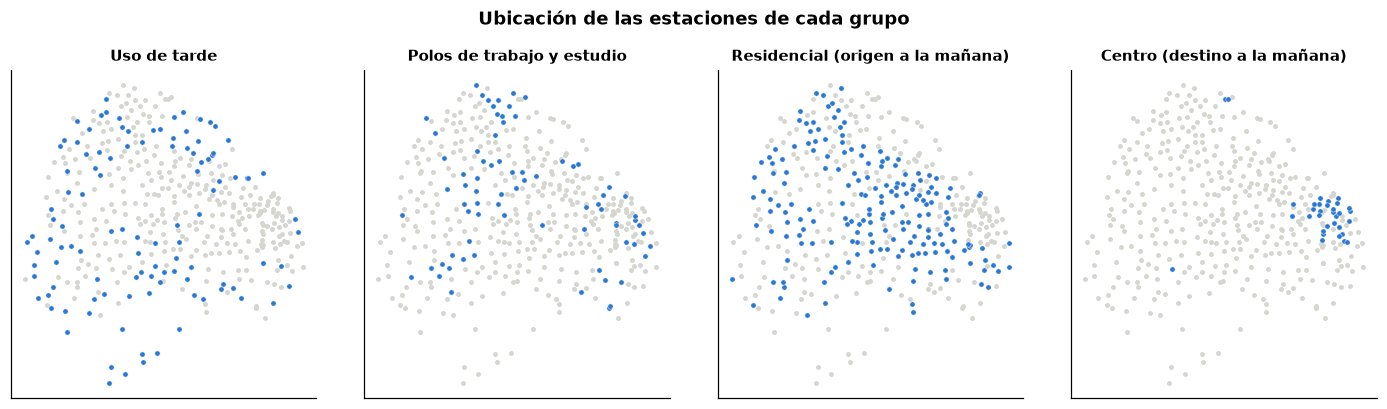

,estaciones,retiros por estación y día,WAPE boosting %,WAPE media histórica %
grupo,,,,
Centro (destino a la mañana),32.0,15.1,30.6,59.8
Polos de trabajo y estudio,73.0,15.9,28.4,49.5
Residencial (origen a la mañana),185.0,16.8,27.4,50.4
Uso de tarde,104.0,14.9,32.3,54.8
poco uso (sin perfil),2.0,5.6,48.9,61.5


In [29]:
ubicacion = estaciones.join(grupo, how="inner")

fig, axes = plt.subplots(1, K, figsize=(13, 3.6), sharex=True, sharey=True)
for g, ax in enumerate(axes):
    ax.scatter(estaciones.lon, estaciones.lat, s=5, color="#d6d6d1")
    sub = ubicacion[ubicacion.grupo == g]
    ax.scatter(sub.lon, sub.lat, s=12, color=BLUE, edgecolor="white", lw=0.3)
    ax.set_title(NOMBRES_GRUPOS[g], fontsize=10)
    ax.set_aspect(1 / np.cos(np.radians(-34.6)))
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Ubicación de las estaciones de cada grupo", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

test_grupo = test.join(grupo, on="station_id")
test_grupo["grupo"] = test_grupo.grupo.map(NOMBRES_GRUPOS).fillna("poco uso (sin perfil)")
diario_grupo = (test_grupo.assign(fecha=test_grupo.ts.dt.floor("D"))
                          .groupby(["grupo", "station_id", "fecha"])[["retiros", "pred_retiros", "base_retiros"]].sum())
(diario_grupo.groupby("grupo")
             .apply(lambda g: pd.Series({"estaciones": g.index.get_level_values("station_id").nunique(),
                                         "retiros por estación y día": g.retiros.mean(),
                                         "WAPE boosting %": 100 * (g.pred_retiros - g.retiros).abs().sum() / g.retiros.sum(),
                                         "WAPE media histórica %": 100 * (g.base_retiros - g.retiros).abs().sum() / g.retiros.sum()}))
             .round(1))

**Lectura.** El boosting reduce el error a casi la mitad del de la media histórica en todos los grupos (WAPE de 27 a 32 % contra 50 a 60 %). Los grupos más difíciles son el de **uso de tarde** (32,3 %), con más uso recreativo y más dependiente del clima, y el **centro** (30,6 %), con los flujos más concentrados.

## 12. Uso de la solución: rebalanceo y ampliación

### 12.1 ¿Qué estaciones se van a vaciar o llenar?

Para cada día hábil del test y cada franja pico se calcula el **flujo neto predicho** de cada estación (arribos − retiros predichos, sumados en la franja). Las 15 con el flujo más negativo son las que hay que **abastecer** antes de la franja; las 15 con el flujo más positivo, las que hay que **descargar**. Se compara con las 15 reales de ese día:

- **Precisión@15:** de las 15 que señala el modelo, cuántas están entre las 15 reales.
- **Spearman:** correlación de rangos entre el flujo neto predicho y el real, sobre todas las estaciones.

In [30]:
FRANJAS = {"mañana (6 a 9 h)": range(6, 10), "tarde (16 a 19 h)": range(16, 20)}
TOP = 15
habiles = test[test.dia_habil == 1].assign(fecha=lambda d: d.ts.dt.floor("D"))


def flujo_neto(horas):
    return (habiles[habiles.hora.isin(horas)]
            .assign(real=lambda d: d.arribos - d.retiros,
                    boosting=lambda d: d.pred_arribos - d.pred_retiros,
                    media_historica=lambda d: d.base_arribos - d.base_retiros)
            .groupby(["fecha", "station_id"])[["real", "boosting", "media_historica"]].sum())


def precision_top(dia, columna, signo):
    reales = set((signo * dia.real).nlargest(TOP).index)
    predichas = set((signo * dia[columna]).nlargest(TOP).index)
    return len(reales & predichas) / TOP


filas = []
for franja, horas in FRANJAS.items():
    for fecha, dia in flujo_neto(horas).groupby(level="fecha"):
        dia = dia.droplevel("fecha")
        for columna in ["boosting", "media_historica"]:
            filas.append({"franja": franja, "modelo": columna, "fecha": fecha,
                          "precisión@15 abastecer": precision_top(dia, columna, -1),
                          "precisión@15 descargar": precision_top(dia, columna, 1),
                          "Spearman": spearmanr(dia.real, dia[columna]).statistic})
rebalanceo = pd.DataFrame(filas)
rebalanceo.groupby(["franja", "modelo"])[["precisión@15 abastecer", "precisión@15 descargar", "Spearman"]].mean().round(3)

precisión@15 abastecer  precisión@15 descargar  Spearman
franja            modelo                                                                   
mañana (6 a 9 h)  boosting                          0.376                   0.497     0.506
                  media_historica                   0.392                   0.445     0.474
tarde (16 a 19 h) boosting                          0.275                   0.277     0.293
                  media_historica                   0.289                   0.283     0.287

**Lectura.**

- **A la mañana**, de las 15 estaciones que el modelo señala para **descargar**, la mitad (50 %) están entre las 15 que efectivamente más se llenaron. Para **abastecer** acierta el 38 %. La correlación de rangos con el flujo real es de 0,51. Elegir 15 estaciones al azar entre ~400 acertaría un 4 %.
- **A la tarde** el rendimiento cae (28 %, Spearman 0,29): los flujos de la tarde están más repartidos entre estaciones y dependen más de cada día.
- **Resultado importante: para ordenar estaciones, el boosting apenas se diferencia de la media histórica.** Es mejor para descargar a la mañana (0,50 contra 0,45) y en Spearman (0,51 contra 0,47), pero algo peor para abastecer (0,38 contra 0,39 a la mañana, 0,28 contra 0,29 a la tarde). Hay tres razones:
  1. **Qué estación se vacía es bastante estructural** (residencial a la mañana, centro a la tarde), y la media histórica lo estima con dos años y medio de datos. Su sesgo de nivel del invierno no la perjudica para *ordenar*, porque afecta a todas las estaciones por igual.
  2. El modelo optimiza la devianza **de cada target por separado, hora por hora**, no la **diferencia** arribos − retiros sumada en la franja: los errores de los dos modelos se suman.
  3. El flujo real está **censurado**: una estación vacía no puede registrar más retiros, y eso achica justamente los flujos que se quieren detectar.

  El boosting sigue siendo mucho mejor para estimar **cuántas** bicis mover (WAPE diario 29 % contra 52 %). Las mejoras para la parte de orden están en la sección 14.

**Ejemplo de salida operativa:** la lista que recibiría el equipo de logística para la mañana del martes 2 de junio de 2026.

In [31]:
ejemplo = flujo_neto(FRANJAS["mañana (6 a 9 h)"]).loc[pd.Timestamp("2026-06-02")].join(estaciones.nombre)
columnas = {"nombre": "estación", "boosting": "flujo neto predicho", "real": "flujo neto real"}
abastecer = ejemplo.nsmallest(10, "boosting")[list(columnas)].rename(columns=columnas)
descargar = ejemplo.nlargest(10, "boosting")[list(columnas)].rename(columns=columnas)
pd.concat({"Abastecer (se vacían)": abastecer.reset_index(drop=True),
           "Descargar (se llenan)": descargar.reset_index(drop=True)}, axis=1).round(1)

Abastecer (se vacían)                                                 Descargar (se llenan)                                    
                       estación flujo neto predicho flujo neto real                          estación flujo neto predicho flujo neto real
0            147 - Constitución               -19.0             -37               026 - JUANA MANSO I                19.4              19
1               130 - RETIRO II               -17.1             -21             035 - INGENIERO BUTTY                13.1               2
2                002 - Retiro I                -9.7             -10               237 - Madero Office                12.1              21
3                014 - Pacifico                -9.6               3              111 - MACACHA GUEMES                11.1              12
4           115 - JUAN DE GARAY                -5.8              -1  227 -Club Ciudad de Buenos Aires                10.0               5
5           276 - PRIMERA JUNTA                -5.2              -5        344 - UNIVERSIDAD DI TELLA                 9.4               8
6                    013 - ONCE                -5.0              -3            137 - AZOPARDO Y CHILE                 7.2               0
7                 163 - ONCE II                -5.0              -5                       036 - MAIPÚ                 5.8               1
8  169 - FACULTAD DE PSICOLOGIA                -4.6              -2                       214 - MORÓN                 5.6               9
9        104 - Federico Lacroze                -4.4              -3         131- HOSPITAL DE CLÍNICAS                 5.6               6

### 12.2 ¿Qué estaciones conviene ampliar?

Una estación es candidata a ampliarse cuando **pierde demanda por falta de capacidad**: se queda sin bicis (o sin lugar) seguido y, cuando eso pasa, había gente que la iba a usar. Para estimar esa demanda perdida se usa el modelo **entrenado sin horas censuradas** (sección 8.1): una **aproximación** de cuántos retiros habría habido si la estación hubiera tenido bicis. Es una aproximación porque ese modelo se entrenó seleccionando horas por el resultado (sección 8.1). Sirve para **ordenar** estaciones, pero los totales hay que leerlos como un orden de magnitud. En las horas en que la estación estuvo vacía o cerrada:

$$\text{retiros perdidos de la estación} = \max\Big(0,\ \sum_{\text{horas censuradas}} (\text{predicción sin censura} - \text{retiros observados})\Big)$$

La diferencia se suma **sin recortar hora por hora**, y el mínimo de 0 se aplica recién al total de la estación. Recortar cada hora (`max(0, …)`) sobreestima: con un conteo, el valor observado cae por debajo de la media muchas veces por puro azar, y esas horas sumarían "demanda perdida" aunque el modelo fuera perfecto. Como **control** se aplican las dos fórmulas a las horas **sin censura**, donde la demanda perdida real es 0.

Se calcula sobre el test, sólo con las horas que tienen fotos (sin fotos no se sabe si la estación estaba vacía).

In [32]:
con_fotos = test[test.sin_fotos == 0].copy()
censurada = ((con_fotos.flag_vacia == 1) | (con_fotos.sin_alquiler == 1)).to_numpy()
limpia = ((con_fotos.flag_vacia == 0) & (con_fotos.sin_alquiler == 0)).to_numpy()
diferencia = (con_fotos.pred_latente - con_fotos.retiros).to_numpy()

control = pd.DataFrame({
    horas: {"horas": mascara.sum(),
            "sin recortar": diferencia[mascara].sum(),
            "recortando cada hora": np.clip(diferencia[mascara], 0, None).sum(),
            "recortando el total de cada estación": pd.Series(diferencia[mascara])
                .groupby(con_fotos.station_id.to_numpy()[mascara]).sum().clip(lower=0).sum()}
    for horas, mascara in [("censuradas", censurada), ("sin censura (control)", limpia)]}).T
print("Retiros perdidos estimados en el test (horas con fotos):")
display(control.round(0))

con_fotos["diferencia_censurada"] = np.where(censurada, diferencia, 0)
dias = con_fotos.assign(fecha=con_fotos.ts.dt.floor("D")).groupby("station_id").fecha.nunique()

ampliacion = (con_fotos.groupby("station_id")
                       .agg(capacidad=("capacidad_publicada", "median"),
                            retiros=("retiros", "sum"), arribos=("arribos", "sum"),
                            perdidos=("diferencia_censurada", "sum"),
                            pct_horas_vacia=("flag_vacia", "mean"),
                            pct_horas_llena_por_rotas=("flag_llena_por_rotas", "mean")))
ampliacion["perdidos"] = ampliacion.perdidos.clip(lower=0)
ampliacion["retiros_por_dia"] = ampliacion.retiros / dias
ampliacion["perdidos_por_dia"] = ampliacion.perdidos / dias
ampliacion["movimientos_por_anclaje"] = (ampliacion.retiros + ampliacion.arribos) / dias / ampliacion.capacidad.replace(0, np.nan)
ampliacion["pct_demanda_perdida"] = 100 * ampliacion.perdidos / (ampliacion.retiros + ampliacion.perdidos)
ampliacion[["pct_horas_vacia", "pct_horas_llena_por_rotas"]] *= 100
ampliacion = ampliacion.join(estaciones.nombre).join(grupo.map(NOMBRES_GRUPOS))

print(f"Total: {ampliacion.perdidos.sum():,.0f} retiros perdidos "
      f"({100 * ampliacion.perdidos.sum() / (ampliacion.retiros.sum() + ampliacion.perdidos.sum()):.1f} % de la demanda de las horas con fotos)")
(ampliacion.sort_values("perdidos_por_dia", ascending=False)
           [["nombre", "grupo", "capacidad", "retiros_por_dia", "perdidos_por_dia", "pct_demanda_perdida",
             "pct_horas_vacia", "pct_horas_llena_por_rotas", "movimientos_por_anclaje"]]
           .head(15).round(1))

Retiros perdidos estimados en el test (horas con fotos):


,horas,sin recortar,recortando cada hora,recortando el total de cada estación
censuradas,82222.0,28950.0,41552.0,28985.0
sin censura (control),513534.0,-2304.0,167169.0,6306.0


Total: 28,985 retiros perdidos (6.3 % de la demanda de las horas con fotos)


,nombre,grupo,capacidad,retiros_por_dia,perdidos_por_dia,pct_demanda_perdida,pct_horas_vacia,pct_horas_llena_por_rotas,movimientos_por_anclaje
station_id,,,,,,,,,
32,032 - Catedral,Centro (destino a la mañana),18.0,14.0,3.7,21.1,54.200001,0.0,1.5
14,014 - Pacifico,Residencial (origen a la mañana),30.0,43.9,3.6,7.6,15.800000,0.0,2.9
444,061 - Ministerio de Economia,Centro (destino a la mañana),24.0,16.1,3.4,17.6,48.500000,0.0,1.3
71,071 - CERRITO,Centro (destino a la mañana),30.0,15.7,3.3,17.5,38.200001,0.0,1.0
111,111 - MACACHA GUEMES,Centro (destino a la mañana),30.0,16.6,3.2,16.3,36.700001,0.0,1.1
4,004 - Plaza Roma,Polos de trabajo y estudio,20.0,23.2,3.1,11.7,35.000000,0.0,2.4
33,033 - Facultad de Medicina,Centro (destino a la mañana),20.0,15.3,3.0,16.6,40.400002,0.0,1.5
3,003 - ADUANA,Centro (destino a la mañana),28.0,16.3,3.0,15.5,41.400002,0.0,1.1
131,131- HOSPITAL DE CLÍNICAS,Polos de trabajo y estudio,16.0,27.9,3.0,9.6,30.400000,0.6,3.4


**Lectura.**

- En las horas del test con fotos se estiman **~29.000 retiros perdidos** por falta de bicis o por estación cerrada, alrededor del **6 % de la demanda** de esas horas. Es un orden de magnitud, no una medición (ver arriba).
- **El control muestra por qué no se recorta hora por hora:** con esa fórmula, las horas **sin censura** sumarían 167.000 retiros "perdidos", que no existen; sobre las censuradas daría 41.600 (8,8 %). Sin recortar, las horas sin censura suman ~−2.300: el modelo latente no tiene sesgo donde había bicis, y los ~6.300 que quedan al recortar el total de cada estación son sólo el efecto de ese recorte. En las censuradas, en cambio, la suma sin recortar (~29.000) casi no cambia al recortar por estación: es demanda que el modelo espera y no se registró.
- **Las candidatas son, sobre todo, estaciones del centro** (Catedral, Ministerio de Economía, Cerrito, Facultad de Medicina, Aduana, Macacha Güemes): están vacías entre el 37 y el 54 % de las horas y pierden entre el 16 y el 21 % de su demanda. Acá el problema **no es la cantidad de anclajes sino de bicis**: se llenan a la mañana, se vacían a la tarde y casi nunca están llenas por bicis rotas. Para ellas la primera respuesta es **rebalancear** (traer bicis a la tarde), no ampliar.
- **Las candidatas a ampliar de verdad son las de alta rotación:** Pacífico (44 retiros por día, segunda en demanda perdida), Hospital de Clínicas (3,4 movimientos por anclaje y por día, 16 anclajes) y Plaza Roma. Pierden demanda aunque se usan intensamente: más anclajes, y más bicis, les permitirían atender más viajes.
- **Límites:**
  - el modelo latente se entrenó seleccionando horas por el resultado (abajo se mide cuánto cambia la estimación con una marca que no lo hace);
  - es sólo invierno;
  - deja afuera las horas sin fotos (21–44 % del test);
  - tampoco incluye los arribos perdidos por estación llena.

**Sensibilidad a la marca de censura.** El modelo latente de arriba se entrenó sin las horas con `flag_vacia` o `sin_alquiler`, que se miden en la misma hora que el target. Se repite la estimación con un modelo latente entrenado **sin las horas que arrancan vacías o cerradas** (sección 8.2), que no selecciona por el resultado. Las horas en las que se mide la pérdida no cambian (las censuradas de arriba): sólo cambia el modelo que estima la demanda. Así, la diferencia mide cuánto dependía la estimación de esa selección.

In [33]:
inicio = time.perf_counter()
modelo_latente_inicio = nuevo_boosting().fit(X.loc[es_train & ~censura_inicio_retiros],
                                             df.loc[es_train & ~censura_inicio_retiros, "retiros"])
print(f"Modelo latente con la marca al inicio de la hora entrenado en {time.perf_counter() - inicio:.0f} s")
pred_latente_inicio = modelo_latente_inicio.predict(X.loc[con_fotos.index])

estacion_con_fotos = con_fotos.station_id.to_numpy()
retiros_con_fotos = con_fotos.retiros.to_numpy()


def perdidos_por_estacion(pred, mascara):
    # misma fórmula que arriba: se suma sin recortar y se recorta el total de cada estación
    return pd.Series(np.where(mascara, pred - retiros_con_fotos, 0)).groupby(estacion_con_fotos).sum().clip(lower=0)


latentes = {"latente de 8.1 (sin censura en la misma hora)": con_fotos.pred_latente.to_numpy(),
            "latente de 8.2 (sin censura al inicio de la hora)": pred_latente_inicio}
perdidos_modelo = {nombre: perdidos_por_estacion(pred, censurada) for nombre, pred in latentes.items()}
sensibilidad_censura = pd.DataFrame({
    nombre: {"retiros perdidos": perdidos_modelo[nombre].sum(),
             "% de la demanda de las horas con fotos": 100 * perdidos_modelo[nombre].sum()
                                                       / (retiros_con_fotos.sum() + perdidos_modelo[nombre].sum()),
             "control: horas sin censura": perdidos_por_estacion(pred, limpia).sum(),
             "sesgo en horas sin censura %": 100 * (pred[limpia].sum() / retiros_con_fotos[limpia].sum() - 1)}
    for nombre, pred in latentes.items()}).T
display(sensibilidad_censura.round(1))

por_dia = {nombre: perdidos / dias.reindex(perdidos.index) for nombre, perdidos in perdidos_modelo.items()}
uno, otro = por_dia.values()
print(f"Ranking de estaciones por retiros perdidos por día: Spearman {spearmanr(uno, otro.reindex(uno.index)).statistic:.2f} · "
      f"coinciden {len(set(uno.nlargest(TOP).index) & set(otro.nlargest(TOP).index))} de las {TOP} primeras")

Modelo latente con la marca al inicio de la hora entrenado en 411 s


,retiros perdidos,% de la demanda de las horas con fotos,control: horas sin censura,sesgo en horas sin censura %
latente de 8.1 (sin censura en la misma hora),28984.7,6.3,6306.3,-0.6
latente de 8.2 (sin censura al inicio de la hora),30394.6,6.6,8786.5,0.8


Ranking de estaciones por retiros perdidos por día: Spearman 1.00 · coinciden 13 de las 15 primeras


**Lectura.**

- **La estimación casi no depende de la marca:** con el modelo latente de 8.2 la demanda perdida es de ~30.400 retiros (6,6 % de la demanda de las horas con fotos), contra ~29.000 (6,3 %) con el de 8.1.
- **El ranking de estaciones es el mismo** (Spearman 1,00), y coinciden 13 de las 15 primeras: las candidatas a ampliar o rebalancear de la tabla de arriba no cambian.
- El control en horas sin censura es algo mayor con el modelo de 8.2 (~8.800 contra ~6.300), porque tiene un sesgo levemente positivo en esas horas (+0,8 % contra −0,6 %). Por eso la demanda perdida se informa como un rango, **entre 6 y 7 %**, y no como una medición.

## 13. Persistencia

Se guarda todo lo necesario para predecir **sin reentrenar**:

| Archivo | Contenido |
|---|---|
| `hgb_retiros.joblib`, `hgb_arribos.joblib` | Modelos principales de boosting (todas las horas) |
| `hgb_retiros_latente.joblib` | Modelo sin horas censuradas: aproximación de la demanda latente, para la sección 12.2 |
| `glm_retiros.joblib` | Regresión de Poisson (pipeline completo con su preprocesamiento), como referencia interpretable |
| `kmeans_perfiles.joblib` | *K-means* de perfiles horarios. Para asignar una estación nueva hay que armar su perfil como en la sección 11; para el uso diario alcanza con `grupos_estaciones.csv` |
| `grupos_estaciones.csv` | Grupo asignado a cada estación |
| `metadata.json` | Variables, hiperparámetros, período de entrenamiento, métricas de test, versiones, la **consulta SQL** que arma las variables, el **clima** que espera el modelo en producción y los resultados de los experimentos de la devolución |

Se usa `joblib` porque es el formato recomendado por scikit-learn para sus modelos. La consulta va en el `metadata.json` porque el modelo sólo sirve si las variables se construyen igual que al entrenar.

In [34]:
artefactos = {
    "hgb_retiros.joblib": modelo_retiros,
    "hgb_arribos.joblib": modelo_arribos,
    "hgb_retiros_latente.joblib": modelo_latente,
    "glm_retiros.joblib": glm_retiros,
    "kmeans_perfiles.joblib": kmeans,
}
for viejo in MODELS_DIR.glob("*.joblib"):  # que no queden modelos de corridas anteriores
    viejo.unlink()
for nombre, objeto in artefactos.items():
    joblib.dump(objeto, MODELS_DIR / nombre, compress=3)
(grupo.to_frame().assign(nombre_grupo=grupo.map(NOMBRES_GRUPOS)).join(estaciones.nombre)
      .to_csv(MODELS_DIR / "grupos_estaciones.csv"))

metadata = {
    "descripcion": "Demanda horaria de Ecobici por estación, para el día siguiente",
    "horizonte": "24 horas del día D, con información disponible al cierre del día D-1",
    "entrenado": pd.Timestamp.now().isoformat(timespec="seconds"),
    "periodo_entrenamiento": [str(df.loc[es_train, "ts"].min()), str(df.loc[es_train, "ts"].max())],
    "variables": VARIABLES,
    "columnas_glm": COLUMNAS_GLM,
    "hiperparametros": HIPERPARAMETROS,
    "ventana_busqueda": [str(BUSQUEDA[0]), str(BUSQUEDA[1])],
    "modelo_latente": "hgb_retiros_latente.joblib, entrenado sin horas con flag_vacia o sin_alquiler",
    "clima": {
        "entrenamiento": "observado (Open-Meteo)",
        "produccion": "pronóstico: última versión publicada antes de las 00:00 del día a predecir (sección 10.7)",
        "metricas_test_retiros_con_pronostico": {k: round(float(v), 4) for k, v in metricas(test.retiros, test.pred_retiros_pronostico).items()},
    },
    "devolucion_tp2": {
        "ablacion_variables_estado": {periodo: {k: round(float(v), 4) for k, v in fila.items()}
                                      for periodo, fila in diferencia_ablacion[["Devianza Poisson", "WAPE diario %"]].iterrows()},
        "demanda_perdida_segun_marca_de_censura": {nombre: round(float(v), 1)
                                                   for nombre, v in sensibilidad_censura["retiros perdidos"].items()},
    },
    "grupos": {str(k): v for k, v in NOMBRES_GRUPOS.items()},
    "metricas_test": {target: tabla.loc["Boosting (Poisson)"].round(4).to_dict()
                      for target, tabla in resultados_test.items()},
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "pandas": pd.__version__, "duckdb": duckdb.__version__},
    "consulta_variables": CONSULTA_VARIABLES,
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

pd.DataFrame([{"archivo": ruta.relative_to(REPO_DIR).as_posix(), "MB": round(ruta.stat().st_size / 1e6, 2)}
              for ruta in sorted(MODELS_DIR.iterdir())])

,archivo,MB
0,models/glm_retiros.joblib,0.00
1,models/grupos_estaciones.csv,0.02
2,models/hgb_arribos.joblib,2.86
3,models/hgb_retiros.joblib,2.86
4,models/hgb_retiros_latente.joblib,2.86
5,models/kmeans_perfiles.joblib,0.00
6,models/metadata.json,0.01


**Control: cargar y predecir sin reentrenar.** La función de abajo usa **sólo** los archivos de `models/` y el dataset procesado: lee la consulta del `metadata.json`, arma las variables con los 29 días previos y predice un día completo con los dos modelos de boosting y, como referencia, con la regresión de Poisson.

**Alcance:** sirve para días que ya están en el dataset (*backtest*), porque toma el calendario y el clima de la grilla del tercer notebook. Para predecir **mañana** de verdad hay que agregar la grilla del día siguiente con su calendario y el **pronóstico** del clima, armado como en la sección 10.7. Es la integración que queda para el próximo entregable: el modelo y la construcción de variables no cambian.

In [35]:
def predecir_dia(fecha, dir_modelos=MODELS_DIR, fuente=DATASET):
    meta = json.loads((dir_modelos / "metadata.json").read_text(encoding="utf-8"))
    modelo_ret = joblib.load(dir_modelos / "hgb_retiros.joblib")
    modelo_arr = joblib.load(dir_modelos / "hgb_arribos.joblib")
    modelo_glm = joblib.load(dir_modelos / "glm_retiros.joblib")
    inicio = pd.Timestamp(fecha)
    desde = (inicio - pd.Timedelta(days=29)).strftime("%Y-%m-%d")  # la ventana más larga es de 28 días
    consulta = meta["consulta_variables"].format(fuente=Path(fuente).as_posix(), desde=desde)
    # Las ventanas se calculan sobre los 29 días previos y recién después se filtra el día
    conexion = duckdb.connect()
    conexion.execute("SET enable_progress_bar = false")
    datos = conexion.execute(
        f"SELECT * FROM ({consulta}) WHERE ts >= ? AND ts < ?",
        [inicio.to_pydatetime(), (inicio + pd.Timedelta(days=1)).to_pydatetime()],
    ).df()
    datos["pred_retiros"] = modelo_ret.predict(datos[meta["variables"]])
    datos["pred_arribos"] = modelo_arr.predict(datos[meta["variables"]])
    datos["pred_glm"] = modelo_glm.predict(datos[meta["columnas_glm"]])
    return datos[["station_id", "ts", "pred_retiros", "pred_arribos", "pred_glm", "retiros", "arribos"]]


inicio = time.perf_counter()
dia = predecir_dia("2026-06-02")
print(f"Predicción del 02/06/2026 desde los archivos: {len(dia):,} estación-hora en {time.perf_counter() - inicio:.0f} s")
en_memoria = test.loc[test.ts.dt.floor("D") == "2026-06-02", ["station_id", "ts", "pred_retiros", "pred_arribos", "pred_glm"]]
comparacion = dia.merge(en_memoria, on=["station_id", "ts"], suffixes=("", "_memoria"))
assert len(comparacion) == len(dia) == len(en_memoria)
assert np.allclose(comparacion.pred_retiros, comparacion.pred_retiros_memoria)
assert np.allclose(comparacion.pred_arribos, comparacion.pred_arribos_memoria)
assert np.allclose(comparacion.pred_glm, comparacion.pred_glm_memoria)
print("Los modelos cargados predicen exactamente lo mismo que los entrenados en este notebook.")
(dia.groupby("station_id")[["pred_retiros", "pred_arribos", "retiros", "arribos"]].sum()
    .join(estaciones.nombre).sort_values("pred_retiros", ascending=False).head(5).round(1))

Predicción del 02/06/2026 desde los archivos: 9,480 estación-hora en 7 s


Los modelos cargados predicen exactamente lo mismo que los entrenados en este notebook.


,pred_retiros,pred_arribos,retiros,arribos,nombre
station_id,,,,,
130,97.3,107.3,100,103,130 - RETIRO II
14,95.3,94.5,85,95,014 - Pacifico
435,77.6,79.7,70,75,227 -Club Ciudad de Buenos Aires
96,77.4,80.4,80,86,096 - Carlos Gardel
29,72.6,72.2,71,59,029 - Parque Centenario


## 14. Reflexión crítica

### 14.1 Rendimiento

| | Validación cruzada (3 pliegues) | Test (jun–ago 2026) |
|---|---|---|
| Devianza de Poisson: boosting / media histórica | 1,152 / 1,269 | 1,009 / 1,157 |
| WAPE diario por estación: boosting / media histórica | 23,0 % / 31,4 % | 29,0 % / 52,1 % (mejor baseline en test: semana anterior, 45,9 %) |
| Boosting con clima pronosticado (sección 10.7) | | devianza 1,011 · WAPE diario 29,8 % |
| Sesgo del boosting | −0,3 % | +0,4 % |

- **El boosting con pérdida de Poisson es el mejor modelo** en los tres pliegues y en test, para retiros y para arribos. Está bien calibrado, no tiene sesgo, sigue la forma diaria de la red (correlación 0,94) y se adapta solo a la estacionalidad, que es justo donde fallan los baselines.
- **La regresión de Poisson** queda en el medio. Aporta interpretabilidad: una hora con lluvia tiene un 25 % menos de retiros, y un feriado un 22 % menos que un día no hábil común.
- **Validación sin sesgo de selección:** los hiperparámetros se eligieron en una ventana aparte (junio a agosto de 2025), anterior a los pliegues, y el test se usó una sola vez.
- **Sobre la pregunta de la cátedra (bicis rotas y estaciones vacías):** las horas censuradas muestran demanda no atendida, que se estima en ~6 % de la demanda de las horas del test con fotos (sección 12.2). Esa estimación orienta qué estaciones ampliar o rebalancear.

- **Sobre la devolución del segundo entregable:** las variables de estado no aportan tampoco con buena cobertura de fotos (10.6); usar el pronóstico en lugar del clima observado cuesta menos de un punto de WAPE diario (10.7); y la demanda perdida queda entre el 6 y el 7 % con las dos marcas de censura (8.2 y 12.2).

### 14.2 Limitaciones

1. **Clima pronosticado: medido, pero no reentrenado.** Con el pronóstico disponible al cierre del día anterior, el WAPE diario pasa de 29,0 % a 29,8 % (sección 10.7). El costo se concentra en los días de lluvia, que el pronóstico detecta mal: ahí el modelo sobreestima un 36 %. Como el modelo se entrenó con clima observado, no sabe cuánto confiar en el pronóstico.
2. **El test es sólo invierno.** La validación cruzada cubre primavera, verano y otoño, y la ablación de 10.6 también se evaluó en primavera, pero el test final mide una sola estación del año.
3. **La censura sólo se conoce con fotos.** La marca al inicio de la hora (8.2) evita seleccionar horas por el resultado, y con ella la demanda perdida casi no cambia (6,6 % contra 6,3 %). Pero en el 27 % del train no hay fotos y la censura no se conoce, y la marca al inicio no ve las horas que se vacían en el camino. La demanda perdida es un orden de magnitud, no una medición.
4. **Para ordenar estaciones de rebalanceo, el modelo no se diferencia de la media histórica** (sección 12.1). El modelo aporta los **volúmenes**; el orden todavía se puede mejorar.
5. **Las variables de estado de la estación no aportan** con este horizonte de 24 h, ni siquiera en el período con buena cobertura de fotos (sección 10.6).
6. **`predecir_dia` sólo funciona sobre días que ya están en el dataset.** Para predecir el día siguiente hace falta armar su grilla con el pronóstico del clima (próximo entregable).
7. **La búsqueda de hiperparámetros fue chica** (10 combinaciones, con el 40 % de los datos). Igual muestra que hay poco para ganar por ese lado.

### 14.3 Mejoras propuestas

1. **Media histórica como variable** (*target encoding* por estación × hora × tipo de día, calculado sin incluir el período que se predice) y el **grupo de la sección 11** como variable. Combina lo estructural, que hoy empata en el orden de estaciones, con la adaptación del boosting.
2. **Un target específico para el rebalanceo:** predecir directamente el flujo neto por franja, y elegir el modelo por precisión@15 y no por devianza horaria.
3. **Censura dentro de la hora:** las fotos permiten saber qué parte de la hora estuvo vacía la estación (`prop_vacia`). En lugar de sacar horas enteras del entrenamiento, se podría ajustar el target por el tiempo en que hubo bicis.
4. **Reentrenar con clima pronosticado** (hay pronósticos desde septiembre de 2024), para que el modelo aprenda cuánto confiar en ellos, sobre todo en la lluvia, y actualizar la predicción durante el día con el pronóstico más reciente.
5. **Intervalos de predicción** (con la distribución de Poisson o con pérdida por cuantiles), para decidir cuántas bicis de margen dejar en cada estación.
6. **Calendario más rico:** vacaciones de invierno y de verano, eventos masivos y partidos.
7. **Un horizonte de 1 hora** con el estado de la estación en la hora anterior, para la operación dentro del día: ahí las fotos probablemente sí aporten.
8. **Reentrenamiento y monitoreo** (MLOps): reentrenar cada mes con los nuevos datos de BA Data y vigilar el sesgo por mes. Es la base del próximo entregable.